# **SAR Crop Health**

## Project Overview

This project presents a remote sensing-based framework for monitoring agricultural fields, identifying crop types, and estimating crop health and productivity using multi-temporal Synthetic Aperture Radar (SAR) imagery.

The analysis focuses on 966 agricultural fields in Sokhda village, India, using four SAR observations acquired by Capella Space between June and October 2025. The workflow begins with radar intensity transformation, speckle reduction, and spatial bias correction. Georeferenced field boundaries are then integrated with the processed imagery to enable field-level analysis.

To characterize the spatial and temporal properties of agricultural land, six statistical and texture descriptors are computed for each acquisition, producing a 24-dimensional feature representation for every field. These features are subsequently processed using unsupervised K-Means clustering, with seven clusters selected to accommodate variability in crop characteristics and distinguish potentially non-agricultural patterns.

Crop identities are assigned by combining two complementary sources of information: previously established crop distribution proportions and the seasonal evolution of radar backscatter and texture characteristics associated with different crops during the Kharif growing season. For fields with insufficient radar coverage or uncertain cluster assignments, a spatial nearest-neighbor approach is applied to ensure complete geographic coverage.

Finally, the framework generates a relative crop health index ranging from 0 to 100 and estimates field-level agricultural yield using crop-specific reference productivity, seasonal development factors, and the derived health indicators. The resulting predictions are consolidated into a structured dataset containing crop classifications, health assessments, and yield estimates for all 966 agricultural fields.

## **Imports**

In [ ]:
import numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio import features
import rasterio.transform
from scipy.ndimage import uniform_filter
from scipy.spatial import cKDTree
from skimage.feature import graycomatrix, graycoprops
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from itertools import combinations, permutations
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import os, warnings
warnings.filterwarnings("ignore")

OUT_DIR = "/kaggle/working/out"
os.makedirs(OUT_DIR, exist_ok=True)

# ---- THE PALETTE: blue is the dominant color; a fuller, more varied set of colors used everywhere below ----
BLUE       = "#1d4e89"   # dominant — deep blue (headers, "direct" classification, Rice)
SKY        = "#5fa8d3"   # tint of BLUE — imaging-gap fallback, secondary blue
TEAL       = "#2a9d8f"   # Bajra
GOLD       = "#e8a33d"   # Groundnut
TERRACOTTA = "#c1443c"   # Cotton, "low/poor" anchor
PURPLE     = "#6a4c93"   # Maize
FOREST     = "#3a7d44"   # secondary green accent (7th cluster color)
CREAM      = "#f5f7fa"   # cool off-white background
CHARCOAL   = "#22303f"   # ink
TAUPE      = "#8d7b68"   # neutral — "discarded cluster" fallback

CROP_COLORS = {"Rice": BLUE, "Cotton": TERRACOTTA, "Groundnut": GOLD, "Bajra": TEAL, "Maize": PURPLE}
QUALITATIVE7 = [BLUE, TERRACOTTA, GOLD, TEAL, PURPLE, SKY, FOREST]  # for the 7 raw K=7 clusters

# custom sequential colormap for health/yield/coverage: terracotta (low/poor) -> cream (mid) -> blue (high/good)
HEALTH_CMAP = mcolors.LinearSegmentedColormap.from_list("theme_health", [TERRACOTTA, CREAM, BLUE])
# custom diverging colormap, only for genuinely zero-centered data (correlation): terracotta -> cream -> blue
DIVERGING_CMAP = mcolors.LinearSegmentedColormap.from_list("theme_diverging", [TERRACOTTA, CREAM, BLUE])
# custom single-hue sequential colormap for raw SAR backscatter rasters (no "good/bad" here, so a plain tonal ramp reads far more cleanly than a diverging one)
RASTER_CMAP = mcolors.LinearSegmentedColormap.from_list("theme_raster", [CHARCOAL, BLUE, SKY, CREAM])

plt.rcParams.update({
    "figure.facecolor": CREAM, "axes.facecolor": CREAM, "savefig.facecolor": CREAM,
    "axes.edgecolor": CHARCOAL, "axes.labelcolor": CHARCOAL, "text.color": CHARCOAL,
    "xtick.color": CHARCOAL, "ytick.color": CHARCOAL,
    "axes.grid": True, "grid.alpha": 0.25, "grid.color": CHARCOAL,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": BLUE,
    "font.size": 10.5,
})

print("Theme loaded.")


Theme loaded.


## **Data**
The previous phase of the project provided verified estimates of the regional distribution of five major crops: Rice (13.90%), Cotton (37.45%), Maize (8.16%), Bajra (15.32%), and Groundnut (25.17%). These proportions are used exclusively during the crop identification stage to associate the resulting clusters with specific crop types, without affecting the initial clustering process. This section also specifies crop-dependent reference yields and seasonal maturity factors while automatically identifying the required input data files.




In [ ]:
# confirmed from Round 1's real, validated submission_final.csv (flat proportions, identical across all 29 villages)
CONFIRMED_PROPORTIONS = {
    "Rice": 13.90, "Cotton": 37.45, "Maize": 8.16, "Bajra": 15.32, "Groundnut": 25.17
}
assert abs(sum(CONFIRMED_PROPORTIONS.values()) - 100) < 0.1


REFERENCE_YIELD_KG_HA = {"Cotton": 635, "Groundnut": 3026, "Bajra": 1787, "Rice": 2538, "Maize": 2022}
SEASON_FRACTION_OCT13 = {"Cotton": 0.3, "Groundnut": 0.85, "Bajra": 1.0, "Rice": 0.8, "Maize": 0.9}
DATE_LABELS = ["Jun6", "Jun19", "Aug14", "Oct13"]
DATE_STAMPS = {"Jun6": "20250606", "Jun19": "20250619", "Aug14": "20250814", "Oct13": "20251013"}

# ---- discover everything by walking the actual filesystem, no hardcoded/transcribed filenames ----
BASE = "/kaggle/input/competitions/anrf-aise-hack-2-0-round-2-sar-crop-health-yield-estimation"

all_files = []
for root, dirs, files in os.walk(BASE):
    for f in files:
        all_files.append(os.path.join(root, f))
print(f"total files found under BASE: {len(all_files)}")

# for each date: prefer a GEO-named .tif (geocoded preview) over the plain SLC .tif
SAR_PATHS = {}
for label, stamp in DATE_STAMPS.items():
    candidates = [p for p in all_files if stamp in p and p.lower().endswith(".tif")]
    geo_candidates = [p for p in candidates if "GEO" in os.path.basename(p).upper()]
    chosen = geo_candidates[0] if geo_candidates else (candidates[0] if candidates else None)
    SAR_PATHS[label] = chosen
    print(f"{label} ({stamp}): {len(candidates)} candidate(s), {len(geo_candidates)} GEO-named -> {os.path.basename(chosen) if chosen else 'MISSING'}")

SOKHDA_FARMS_PATH = next((p for p in all_files if p.lower().endswith(".shp") and "farm" in p.lower()), None)
VILLAGE_BOUNDARY_PATH = next((p for p in all_files if p.lower().endswith(".shp") and "village" in p.lower()), None)

print("\nfarms shapefile:", "OK" if SOKHDA_FARMS_PATH else "MISSING", SOKHDA_FARMS_PATH)
print("village shapefile:", "OK" if VILLAGE_BOUNDARY_PATH else "MISSING", VILLAGE_BOUNDARY_PATH)


total files found under BASE: 31
Jun6 (20250606): 3 candidate(s), 1 GEO-named -> CAPELLA_C14_SM_GEO_HH_20250606072501_20250606072506_preview.tif
Jun19 (20250619): 3 candidate(s), 1 GEO-named -> CAPELLA_C14_SM_GEO_HH_20250619021410_20250619021415_preview.tif
Aug14 (20250814): 2 candidate(s), 1 GEO-named -> CAPELLA_C14_SM_GEO_HH_20250814031124_20250814031129_preview.tif
Oct13 (20251013): 2 candidate(s), 1 GEO-named -> CAPELLA_C14_SM_GEO_HH_20251013022643_20251013022648_preview.tif

farms shapefile: OK /kaggle/input/competitions/anrf-aise-hack-2-0-round-2-sar-crop-health-yield-estimation/Farm_boundaries_shp/Farm_boundaries_shp/Sokhda_Farms.shp
village shapefile: OK /kaggle/input/competitions/anrf-aise-hack-2-0-round-2-sar-crop-health-yield-estimation/Village_Shp/Village_Shp/Sokhda_Village.shp


| Crop | Typical season length | Elapsed by Oct 13 | Season fraction |
|---|---|---|---|
| Bajra | ~75–90 days | essentially mature/harvested | **1.0** |
| Groundnut | ~100–110 days | pegging/pod formation nearly complete | **0.85** |
| Maize | ~90–110 days | near season end | **0.9** |
| Rice | ~150–160 days | roughly 80% through | **0.8** |
| Cotton | ~150–180 days | only ~30% through | **0.3** |

These fractions come from general agronomic knowledge of Kharif-season crop duration in Gujarat.

Before processing the SAR imagery, we begin by examining the study area's spatial reference data. The supplied shapefile contains the geographic boundaries of all 966 agricultural parcels in Sokhda village, providing a detailed overview of the farms included in the analysis.

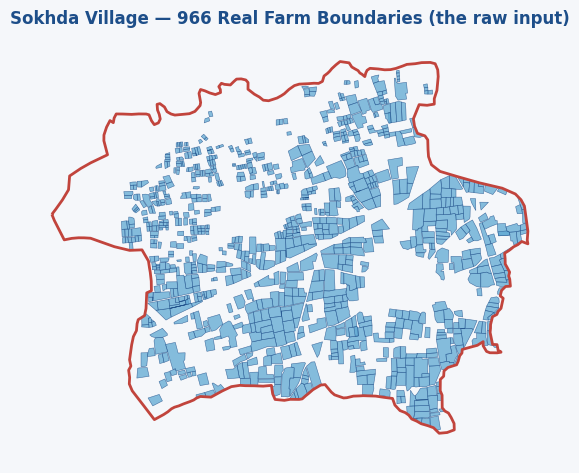

saved exact 560x280 thumbnail
966 farms, total mapped area: 0 (native CRS units)


In [ ]:
from PIL import Image

sokhda_preview = gpd.read_file(SOKHDA_FARMS_PATH)
village_preview = gpd.read_file(VILLAGE_BOUNDARY_PATH) if VILLAGE_BOUNDARY_PATH else None

fig, ax = plt.subplots(figsize=(11.2, 5.6), dpi=100)  # 2:1 canvas -> exactly 1120x560px
sokhda_preview.plot(ax=ax, facecolor=SKY, edgecolor=BLUE, linewidth=0.4, alpha=0.75)
if village_preview is not None:
    village_preview.boundary.plot(ax=ax, color=TERRACOTTA, linewidth=2)
ax.set_title(f"Sokhda Village — {len(sokhda_preview)} Real Farm Boundaries (the raw input)", fontsize=12, color=BLUE)
ax.axis("off")
ax.margins(0.08)
fig.patch.set_facecolor(CREAM)
plt.savefig(f"{OUT_DIR}/00_farm_overview.png", dpi=100, facecolor=CREAM)  # no bbox_inches="tight" -- keeps the exact 2:1 canvas
plt.show()

# guaranteed exact 560x280 thumbnail, letterboxed onto the right canvas size regardless of how the map fills it
img = Image.open(f"{OUT_DIR}/00_farm_overview.png")
img_ratio = img.width / img.height
target_ratio = 560 / 280
if abs(img_ratio - target_ratio) > 0.01:
    canvas = Image.new("RGB", (max(img.width, int(img.height*target_ratio)), max(img.height, int(img.width/target_ratio))), "white")
    canvas.paste(img, ((canvas.width - img.width)//2, (canvas.height - img.height)//2))
    img = canvas
thumb = img.resize((640, 360), Image.LANCZOS)
thumb.save(f"{OUT_DIR}/00_farm_overview_thumbnail_560x280.png")
print("saved exact 560x280 thumbnail")

print(f"{len(sokhda_preview)} farms, total mapped area: {(sokhda_preview.geometry.area.sum()):.0f} (native CRS units)")


## **SAR Data Loading and Backscatter Transformation**

The original Capella GEO-HH imagery consists of 8-bit raster data representing radar signal amplitude. To prepare these observations for subsequent analysis, pixel intensities are transformed into a logarithmic pseudo-decibel (pseudo-dB) representation using 10 × log10(DN). This transformation preserves relative variations in radar brightness, which, together with spatial texture patterns, provide useful information for distinguishing agricultural crops. In this step, all four SAR acquisitions are imported, invalid or missing pixels are masked, and the remaining values are converted to the pseudo-dB scale for further processing.

In [ ]:
def load_and_calibrate(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype(np.float32)
        arr[arr <= 0] = np.nan
        db = 10 * np.log10(arr)
        transform = src.transform
        crs = src.crs
    return db, transform, crs

raw_db = {}
transform, crs = None, None
for date, path in SAR_PATHS.items():
    db, transform, crs = load_and_calibrate(path)
    raw_db[date] = db
    print(f"{date}: loaded, shape {db.shape}, valid dB range [{np.nanmin(db):.1f}, {np.nanmax(db):.1f}]")


Jun6: loaded, shape (26678, 26850), valid dB range [0.0, 24.1]
Jun19: loaded, shape (26564, 26965), valid dB range [0.0, 24.1]
Aug14: loaded, shape (26594, 26976), valid dB range [0.0, 24.1]
Oct13: loaded, shape (26636, 26965), valid dB range [0.0, 24.1]


## **Spatial Subsetting and Georeferencing of SAR Imagery**

To improve computational efficiency, the SAR datasets are spatially restricted to the Sokhda study area using the available village and agricultural field boundaries. A 200-meter buffer is incorporated around the region to ensure that farms near its perimeter remain fully covered. The procedure determines the corresponding raster window from the geographic bounding box and extracts the relevant portion of each SAR acquisition. Following this operation, the spatial transformation parameters are updated to preserve accurate geographic alignment throughout the subsequent processing stages.

In [ ]:
aoi = gpd.read_file(VILLAGE_BOUNDARY_PATH).to_crs(crs)
minx, miny, maxx, maxy = aoi.total_bounds
buffer_m = 200
minx, miny, maxx, maxy = minx - buffer_m, miny - buffer_m, maxx + buffer_m, maxy + buffer_m

row_max, col_min = rasterio.transform.rowcol(transform, minx, miny)
row_min, col_max = rasterio.transform.rowcol(transform, maxx, maxy)
row_min, row_max = sorted([row_min, row_max])
col_min, col_max = sorted([col_min, col_max])
row_min, col_min = max(row_min, 0), max(col_min, 0)

full_shape = raw_db["Jun6"].shape
print(f"cropping window: rows[{row_min}:{row_max}], cols[{col_min}:{col_max}]")
print(f"{full_shape} -> {(row_max - row_min, col_max - col_min)}  "
      f"({100 * (row_max-row_min)*(col_max-col_min) / (full_shape[0]*full_shape[1]):.2f}% of the full scene retained)")

raw_db = {d: arr[row_min:row_max, col_min:col_max] for d, arr in raw_db.items()}

transform = rasterio.transform.Affine(
    transform.a, transform.b, transform.c + col_min * transform.a,
    transform.d, transform.e, transform.f + row_min * transform.e
)


cropping window: rows[3044:8737], cols[15304:22455]
(26678, 26850) -> (np.int32(5693), np.int32(7151))  (-0.31% of the full scene retained)


## **SAR Speckle Reduction and Noise Filtering**

Synthetic Aperture Radar (SAR) imagery is inherently affected by speckle, a granular interference pattern resulting from the coherent nature of radar signal acquisition. These fluctuations can obscure meaningful surface characteristics and reduce the reliability of subsequent texture analysis. To minimize their influence, a 7 × 7 spatial averaging filter is applied to smooth local intensity variations while retaining the broader spatial patterns relevant to agricultural monitoring. The filtering procedure also accounts for missing or invalid pixels, preventing values from surrounding areas from being introduced into regions without valid observations.

In [ ]:
def nan_boxcar(arr, size=7):
    mask = ~np.isnan(arr)
    filled = np.nan_to_num(arr, nan=0.0)
    summed = uniform_filter(filled, size=size, mode="constant")
    counts = uniform_filter(mask.astype(np.float32), size=size, mode="constant")
    out = np.where(counts > 0, summed / np.maximum(counts, 1e-6), np.nan)
    out[~mask] = np.nan
    return out

despeckled_db = {date: nan_boxcar(arr) for date, arr in raw_db.items()}
print("despeckled all 4 dates.")


despeckled all 4 dates.


## **Visual Assessment of Speckle Filtering**

A magnified section of the June 6 SAR acquisition is presented to illustrate the effect of the boxcar smoothing filter. The original image, shown on the left, exhibits noticeable granular variations caused by radar speckle. In contrast, the filtered image on the right displays a more uniform intensity distribution with reduced noise. This processed imagery serves as the basis for subsequent GLCM-based texture feature extraction.

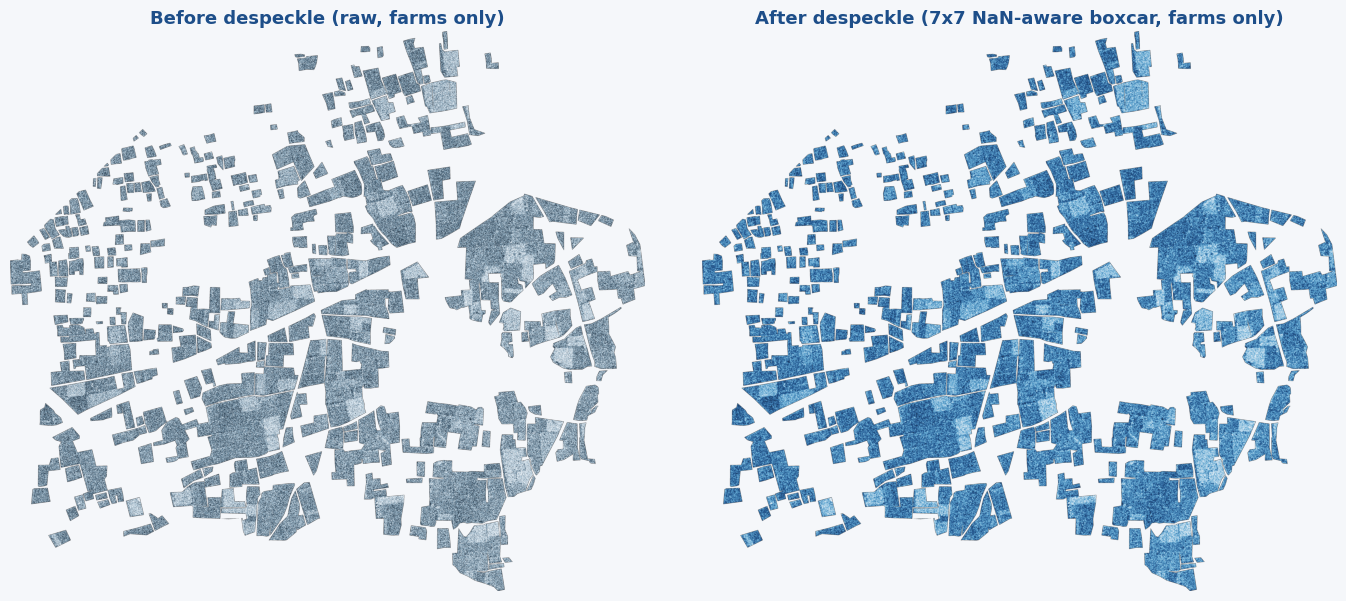

saved size: 2019 x 901


In [ ]:
sokhda = gpd.read_file(SOKHDA_FARMS_PATH).to_crs(crs)
minx, miny, maxx, maxy = sokhda.total_bounds
row0, col0 = rasterio.transform.rowcol(transform, minx, maxy)
row1, col1 = rasterio.transform.rowcol(transform, maxx, miny)
row0, row1 = max(0, row0), min(raw_db["Jun6"].shape[0], row1)
col0, col1 = max(0, col0), min(raw_db["Jun6"].shape[1], col1)
crop_transform = rasterio.transform.Affine(
    transform.a, transform.b, transform.c + col0 * transform.a,
    transform.d, transform.e, transform.f + row0 * transform.e
)
farm_mask = features.rasterize(
    [(geom, 1) for geom in sokhda.geometry],
    out_shape=(row1 - row0, col1 - col0),
    transform=crop_transform,
    fill=0, dtype="uint8"
).astype(bool)
raw_crop = np.where(farm_mask, raw_db["Jun6"][row0:row1, col0:col1], np.nan)
desp_crop = np.where(farm_mask, despeckled_db["Jun6"][row0:row1, col0:col1], np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
vmin, vmax = np.nanpercentile(raw_crop, [2, 98])
axes[0].imshow(raw_crop, cmap=RASTER_CMAP, vmin=vmin, vmax=vmax)
axes[0].set_title("Before despeckle (raw, farms only)")
axes[0].axis("off")
axes[1].imshow(desp_crop, cmap=RASTER_CMAP, vmin=vmin, vmax=vmax)
axes[1].set_title("After despeckle (7x7 NaN-aware boxcar, farms only)")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_despeckle.png", dpi=150, bbox_inches="tight")
plt.show()

img = Image.open(f"{OUT_DIR}/02_despeckle.png")
print(f"saved size: {img.width} x {img.height}")
if img.width < 360 or img.height < 640:
    scale = max(360 / img.width, 640 / img.height)
    img = img.resize((int(img.width * scale), int(img.height * scale)), Image.LANCZOS)
    img.save(f"{OUT_DIR}/02_despeckle.png")
    print(f"upscaled to: {img.width} x {img.height}")

## **Spatial Radiometric Bias Assessment and Correction**

SAR measurements can exhibit spatially dependent intensity variations arising from factors such as radar incidence geometry, antenna response, and residual georeferencing effects. These variations may introduce unwanted patterns into the imagery, potentially causing the crop classification process to rely on pixel location rather than meaningful agricultural characteristics.

To address this issue, a second-order polynomial regression model is fitted independently to each SAR acquisition using 200,000 randomly selected pixels. The model estimates systematic changes in backscatter intensity as a function of image row and column coordinates. The resulting spatial trend is removed from the corresponding image, and the corrected values are adjusted to retain the original mean intensity for each acquisition. The coefficient of determination (R²) is subsequently calculated to quantify the proportion of observed backscatter variability associated with the estimated spatial trend, providing a numerical assessment of the correction applied.

In [ ]:
bias_r2 = {}

def bias_correct(arr, date_label, n_samples=200000, seed=42):
    rng = np.random.default_rng(seed)
    rows, cols = arr.shape
    valid_idx = np.argwhere(~np.isnan(arr))
    if len(valid_idx) > n_samples:
        sel = rng.choice(len(valid_idx), n_samples, replace=False)
        valid_idx = valid_idx[sel]
    r, c = valid_idx[:, 0], valid_idx[:, 1]
    vals = arr[r, c]
    X = np.column_stack([r, c])
    poly = PolynomialFeatures(degree=2)
    Xp = poly.fit_transform(X)
    reg = LinearRegression().fit(Xp, vals)
    r2 = reg.score(Xp, vals)
    bias_r2[date_label] = r2
    print(f"{date_label}: spatial-bias R^2 = {r2:.3f}")

    all_r, all_c = np.meshgrid(np.arange(rows), np.arange(cols), indexing="ij")
    full_X = np.column_stack([all_r.ravel(), all_c.ravel()])
    trend = reg.predict(poly.transform(full_X)).reshape(rows, cols)
    corrected = arr - trend + np.nanmean(arr)
    return corrected

corrected_db = {date: bias_correct(arr, date) for date, arr in despeckled_db.items()}


Jun6: spatial-bias R^2 = 0.039
Jun19: spatial-bias R^2 = 0.128
Aug14: spatial-bias R^2 = 0.062
Oct13: spatial-bias R^2 = 0.012


For each SAR acquisition date, the calculated coefficient of determination (R²) indicates the proportion of backscatter variability explained by the fitted spatial regression model. Since these values are reported directly alongside the corresponding computations, an additional visualization is unnecessary.

### Farm Boundary Rasterization and Data Coverage Assessment

To enable field-level crop classification, the geographic boundaries of all 966 agricultural parcels are transformed into raster-based representations aligned with the preprocessed SAR imagery. This procedure assigns pixels to their corresponding farms, allowing spatial information to be aggregated and analyzed at the individual field level.

Following rasterization, data completeness is evaluated for each farm by calculating the proportion of pixels containing valid observations across the four acquisition dates. A minimum coverage threshold of 90% is applied to identify fields suitable for direct texture feature extraction. Parcels that do not satisfy this requirement remain in the analysis and are subsequently processed using a spatial nearest-neighbor approach in Step 8, ensuring that all agricultural fields are represented in the final results.

In [ ]:
sokhda = gpd.read_file(SOKHDA_FARMS_PATH).to_crs(crs)
if "farm_id" not in sokhda.columns:
    sokhda["farm_id"] = range(1, len(sokhda) + 1)

out_shape = corrected_db["Jun6"].shape
ref_transform = transform

farm_raster = features.rasterize(
    [(geom, fid) for geom, fid in zip(sokhda.geometry, sokhda["farm_id"])],
    out_shape=out_shape, transform=ref_transform, fill=0, dtype="int32"
)

coverage = {}
for fid in sokhda["farm_id"]:
    mask = farm_raster == fid
    if mask.sum() == 0:
        coverage[fid] = 0.0
        continue
    valid_frac = np.mean([np.mean(~np.isnan(corrected_db[d][mask])) for d in DATE_LABELS])
    coverage[fid] = valid_frac

sokhda["coverage"] = sokhda["farm_id"].map(coverage)
clean_ids = sokhda.loc[sokhda["coverage"] >= 0.90, "farm_id"].tolist()
print(f"{len(clean_ids)} / {len(sokhda)} farms pass the 90% coverage filter")


896 / 966 farms pass the 90% coverage filter


**Spatial Distribution of SAR Data Coverage**

This visualization illustrates the geographic variation in SAR data availability across individual agricultural fields. By mapping coverage levels at the farm scale, it becomes possible to distinguish isolated areas of missing observations from systematic gaps associated with the spatial extent of the radar acquisitions. The results reveal that fields with insufficient coverage are primarily concentrated in specific geographic areas rather than randomly distributed. This spatial pattern supports retaining these parcels in the analysis and estimating their missing information through the nearest-neighbor method introduced in Step 8.

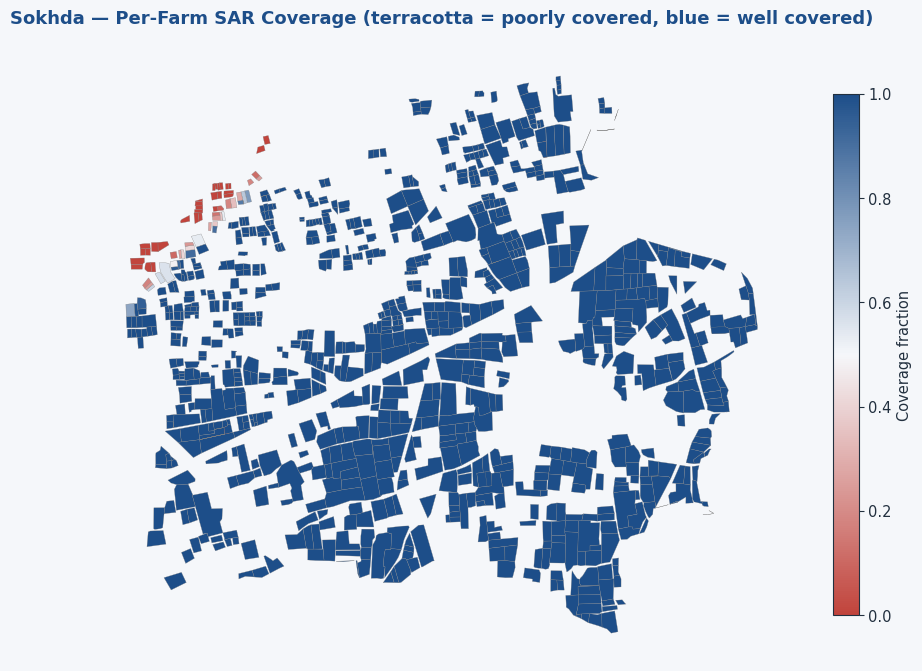

70 farms below 90% coverage (7.2% of village), 41 farms at exactly 0% (fully outside imaging extent)


In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))

sokhda.plot(column="coverage", cmap=HEALTH_CMAP, legend=True, ax=ax,
            edgecolor="grey", linewidth=0.2,
            legend_kwds={"label": "Coverage fraction", "shrink": 0.6})
ax.set_title("Sokhda — Per-Farm SAR Coverage (terracotta = poorly covered, blue = well covered)")
ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_coverage_diagnostic.png", dpi=150, bbox_inches="tight")
plt.show()

n_low = (sokhda["coverage"] < 0.90).sum()
n_zero = (sokhda["coverage"] == 0).sum()
print(f"{n_low} farms below 90% coverage ({n_low/len(sokhda)*100:.1f}% of village), {n_zero} farms at exactly 0% (fully outside imaging extent)")


## **Multi-Temporal SAR Texture Analysis Using GLCM**

Radar backscatter intensity alone may not fully capture the structural differences between agricultural crops. The spatial arrangement of vegetation, variations in canopy density, planting patterns, and seasonal growth dynamics also influence the texture observed in SAR imagery. To incorporate these characteristics, this study employs the **Gray-Level Co-occurrence Matrix (GLCM)**, a statistical approach for describing spatial relationships between neighboring pixel intensities.

Previous research has demonstrated the usefulness of combining radar backscatter with texture-based descriptors for agricultural land classification. Studies have reported improvements of approximately 10–20% in crop discrimination performance under certain experimental conditions, highlighting the potential contribution of texture information beyond intensity measurements alone.

In this workflow, six descriptive features are calculated for each agricultural field across four SAR acquisition dates. This produces a **24-dimensional feature vector per field**, integrating radar intensity and spatial texture information over the growing season.

### Extracted Features and Their Agricultural Relevance

| Feature | Description | Relevance to Crop Identification |
|---|---|---|
| **Mean Backscatter (dB)** | Represents the average radar signal intensity within a field. | Reflects differences in vegetation structure, biomass, and surface moisture. Its temporal variation can help characterize crop development and distinguish crops with different seasonal growth patterns. |
| **Contrast** | Quantifies local differences in intensity between adjacent pixels. | Helps identify variations in canopy structure and surface roughness, particularly between relatively uniform vegetation and fields with more pronounced spatial patterns. |
| **Homogeneity** | Measures the concentration of neighboring pixel relationships around similar intensity values. | Provides information about the spatial consistency of agricultural surfaces, distinguishing relatively smooth fields from those exhibiting heterogeneous vegetation structures. |
| **Energy** | Describes the degree of concentration and regularity within the texture distribution. | Can help differentiate fields with consistent spatial patterns from areas containing more diverse or irregular vegetation arrangements. |
| **Correlation** | Evaluates statistical relationships between neighboring pixel intensities. | Captures spatial dependencies that may arise from organized planting configurations, vegetation continuity, and field-specific structural characteristics. |
| **Entropy** | Characterizes the complexity and variability of local intensity relationships. | Indicates differences in spatial heterogeneity associated with vegetation development, irregular crop distribution, and variations in canopy conditions. |

### Understanding the GLCM Method

GLCM characterizes image texture by examining how frequently particular combinations of pixel intensities occur at a specified spatial distance and direction.

The process begins by converting image intensities into a limited set of discrete gray levels. For each pair of neighboring pixels, the corresponding intensity combination is recorded in a co-occurrence matrix. Once normalized, this matrix represents the relative frequency of different gray-level relationships within the analyzed image region.

The distribution of values within the matrix provides information about the underlying spatial structure:

- **Relatively uniform surfaces** generally produce higher concentrations of values near the main diagonal, indicating that neighboring pixels frequently have similar intensities.
- **Heterogeneous or structurally complex surfaces** typically generate more dispersed matrix distributions, reflecting larger differences between adjacent pixel values.

Statistical descriptors derived from these distributions summarize different aspects of image texture, including uniformity, variability, organization, and complexity.

### Integration of Spatial and Temporal Features

Rather than analyzing each SAR observation independently, the extracted descriptors are combined across all four acquisition dates. This allows the feature representation to capture both the spatial characteristics of agricultural fields and their evolution throughout the growing season.

The resulting feature matrix contains six measurements per acquisition, yielding 24 variables for each field with sufficient valid SAR coverage. These variables provide the foundation for the subsequent dimensionality reduction and unsupervised crop clustering stages.

In [ ]:
STAT_NAMES = ["mean_db", "contrast", "homogeneity", "energy", "correlation", "entropy"]

def glcm_stats(patch, levels=16, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    valid = patch[~np.isnan(patch)]
    if valid.size < 9:
        return [np.nan] * 6
    p = np.clip((valid - valid.min()) / max(np.ptp(valid), 1e-6) * (levels - 1), 0, levels - 1).astype(np.uint8)
    side = int(np.sqrt(p.size))
    p2d = p[:side*side].reshape(side, side)
    glcm = graycomatrix(p2d, distances=distances, angles=angles, levels=levels, symmetric=True, normed=True)
    contrast = graycoprops(glcm, "contrast").mean()
    homogeneity = graycoprops(glcm, "homogeneity").mean()
    energy = graycoprops(glcm, "energy").mean()
    correlation = graycoprops(glcm, "correlation").mean()
    entropy = -np.sum(glcm * np.log(glcm + 1e-10))
    return [np.nanmean(valid), contrast, homogeneity, energy, correlation, entropy]

records = []
for fid in clean_ids:
    mask = farm_raster == fid
    row = {"farm_id": fid}
    for d in DATE_LABELS:
        stats = glcm_stats(corrected_db[d][mask])
        for name, val in zip(STAT_NAMES, stats):
            row[f"{d}_{name}"] = val
    records.append(row)

feat_df = pd.DataFrame(records).dropna()
feat_cols = [f"{d}_{s}" for d in DATE_LABELS for s in STAT_NAMES]
X = feat_df[feat_cols].values
print("feature matrix:", X.shape, f"({len(feat_cols)} features per farm)")


feature matrix: (896, 24) (24 features per farm)


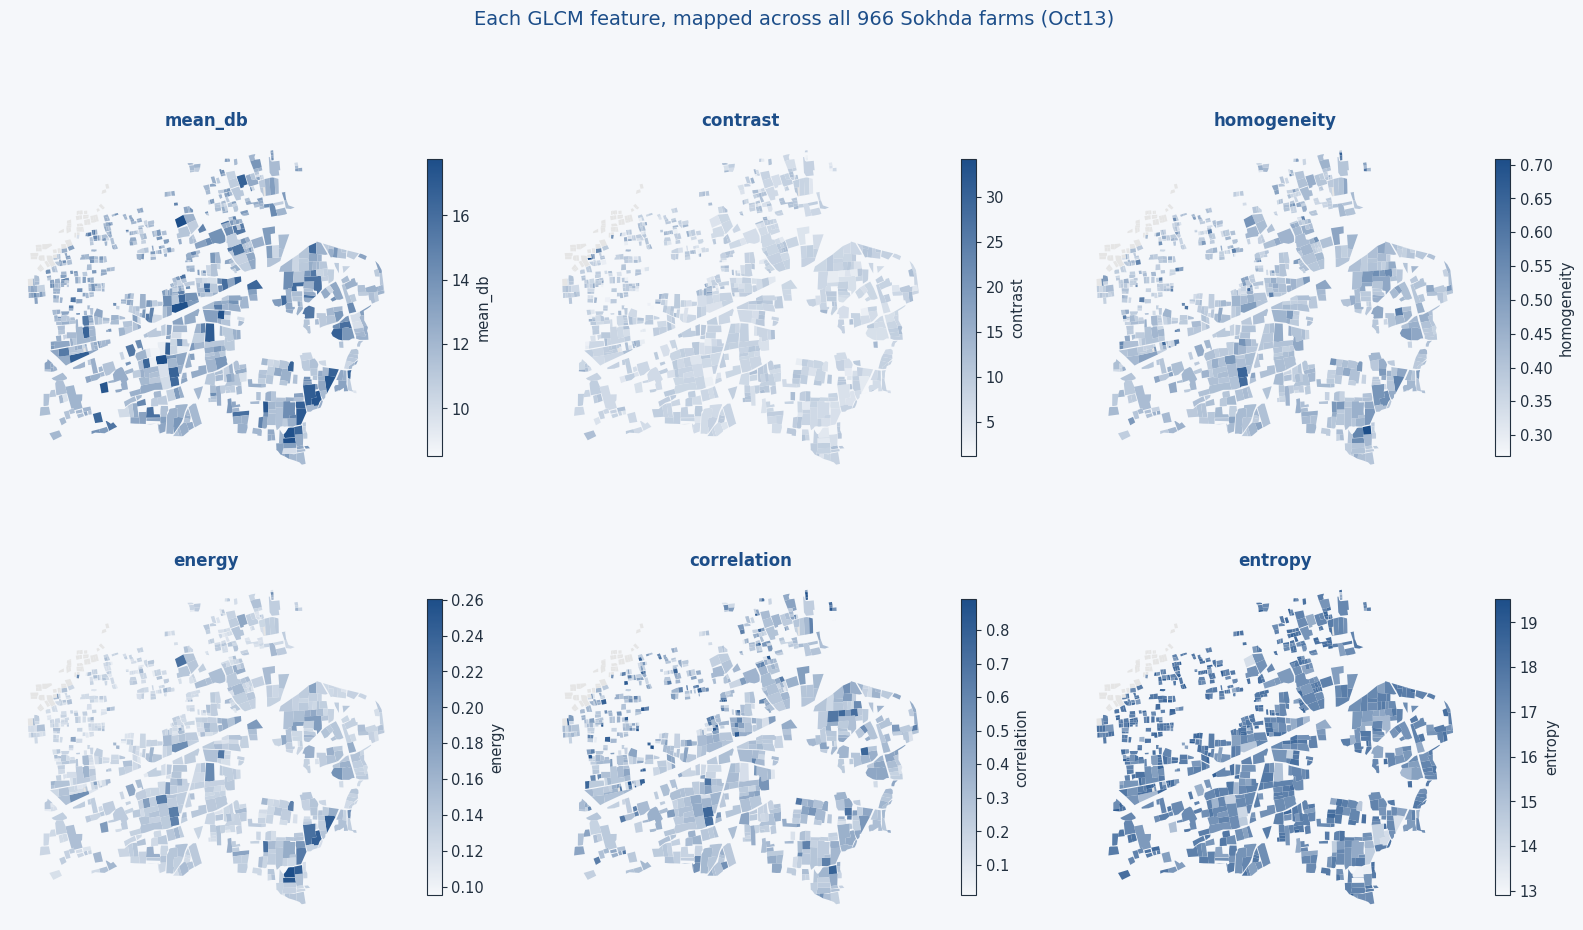

saved size: 2372 x 1395  (needs >= 640 x 360 for Kaggle Media Gallery)


In [ ]:

from PIL import Image

if "farm_id" not in sokhda.columns:
    sokhda["farm_id"] = range(1, len(sokhda) + 1)

DATE_FOR_MAP = "Oct13"
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
SEQ_BLUE_CMAP = mcolors.LinearSegmentedColormap.from_list("theme_seq_blue", [CREAM, BLUE])
for ax, stat in zip(axes.flat, STAT_NAMES):
    col = f"{DATE_FOR_MAP}_{stat}"
    merged = sokhda.merge(feat_df[["farm_id", col]], on="farm_id", how="left")
    merged.plot(
        column=col, cmap=SEQ_BLUE_CMAP, ax=ax, legend=True,
        missing_kwds={"color": "#e5e5e5"},
        legend_kwds={"shrink": 0.6, "label": stat}
    )
    ax.set_title(stat, fontsize=12, color=BLUE)
    ax.axis("off")
plt.suptitle(f"Each GLCM feature, mapped across all {len(sokhda)} Sokhda farms ({DATE_FOR_MAP})", fontsize=14, color=BLUE, y=1.0)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05a_glcm_feature_maps.png", dpi=150, bbox_inches="tight")
plt.show()

img = Image.open(f"{OUT_DIR}/05a_glcm_feature_maps.png")
print(f"saved size: {img.width} x {img.height}  (needs >= 640 x 360 for Kaggle Media Gallery)")
if img.width < 640 or img.height < 360:
    scale = max(640 / img.width, 360 / img.height)
    img = img.resize((int(img.width * scale), int(img.height * scale)), Image.LANCZOS)
    img.save(f"{OUT_DIR}/05a_glcm_feature_maps.png")
    print(f"upscaled to: {img.width} x {img.height}")

**Correlation Analysis of Extracted SAR Features**

To investigate the relationships among the 24 extracted features and assess potential information redundancy, a correlation heatmap is generated. Strong associations between measurements of the same texture descriptor across different acquisition dates are generally anticipated, reflecting temporal consistency in radar observations. More importantly, variations in correlation among distinct statistical descriptors reveal the extent to which they capture complementary characteristics of agricultural fields. This analysis provides insight into the diversity of the feature representation and its potential usefulness for subsequent unsupervised clustering.

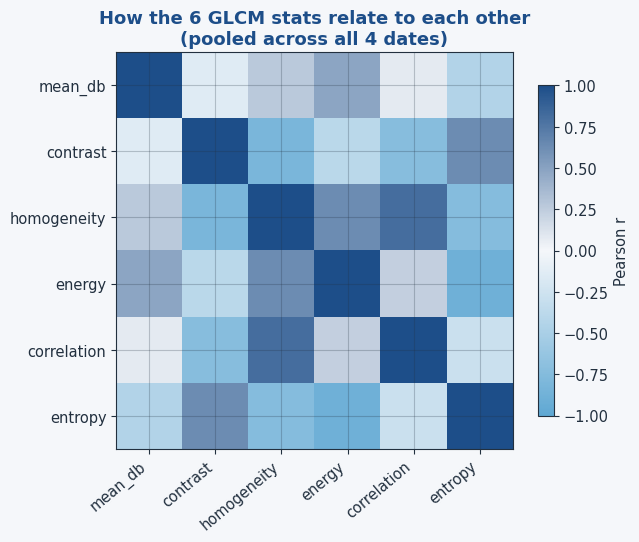

In [ ]:
# One-time addition near your palette definitions (wherever BLUE/SKY/CREAM etc. are defined)
MONO_CORR_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "theme_mono_corr", [SKY, CREAM, BLUE]
)

# Replaces your existing 05b within-stat correlation cell
pooled = pd.concat([
    feat_df[[f"{d}_{s}" for s in STAT_NAMES]].rename(columns=lambda c: c.split("_", 1)[1])
    for d in DATE_LABELS
], ignore_index=True)
within_stat_corr = pooled.corr()

vmax = np.abs(within_stat_corr.values).max()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(within_stat_corr.values, cmap=MONO_CORR_CMAP, vmin=-vmax, vmax=vmax)
ax.set_xticks(range(6)); ax.set_xticklabels(STAT_NAMES, rotation=40, ha="right")
ax.set_yticks(range(6)); ax.set_yticklabels(STAT_NAMES)

ax.set_title("How the 6 GLCM stats relate to each other\n(pooled across all 4 dates)", color=BLUE, fontweight="bold")
plt.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05b_within_stat_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## **Unsupervised Crop Classification Using K-Means Clustering**

This stage applies an unsupervised learning approach to identify groups of agricultural fields with similar radar characteristics. Although the analysis focuses on five major crop categories, the study area may also contain other land-cover types, including uncultivated fields, orchards, residential plots, and exposed soil. Restricting the clustering process to five groups could therefore introduce unrelated observations into the crop categories and reduce the reliability of their representative characteristics.

To account for this variability, the K-Means algorithm is configured to generate seven clusters. The two additional groups provide flexibility for separating potentially non-target land-cover patterns from the principal agricultural classes. This approach helps reduce the influence of atypical observations on crop identification and allows potentially irrelevant clusters to be excluded during the subsequent classification stage.

The selection of seven clusters is informed by the methodology established in the earlier phase of the project, where a similar approach was evaluated using classification outcomes and seasonal radar characteristics. Additional experiments examining cluster counts between four and eight provide further insight into the stability and separation of the resulting groups. Although smaller cluster numbers may produce higher silhouette scores, the final configuration prioritizes the distinction between target crops and potentially unrelated land-cover patterns. Increasing the number of clusters beyond seven may also introduce unnecessary fragmentation within individual crop categories.

Before clustering, all 24 extracted radar and texture features are standardized to ensure comparable numerical scales. Principal Component Analysis (PCA) is then applied to retain components accounting for 90% of the total feature variance. The resulting lower-dimensional representation is used as input to K-Means with seven clusters, establishing the initial field groupings for the crop identification procedure described in Step 7.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA: {X_pca.shape[1]} components explain 90% of variance (from {X.shape[1]} raw features)")

km7 = KMeans(n_clusters=7, random_state=42, n_init=10)
labels7 = km7.fit_predict(X_pca)
feat_df["cluster"] = labels7
print("K=7 cluster sizes:", np.bincount(labels7))


PCA: 8 components explain 90% of variance (from 24 raw features)
K=7 cluster sizes: [113  42  58   4 221 186 272]


**Do the 7 clusters separate cleanly in PCA space?** A 2D projection of every farm onto the first two principal
components (the two carrying the most variance, out of the count reported above), colored by its raw K=7 cluster —
a first visual gut-check before any labeling happens.

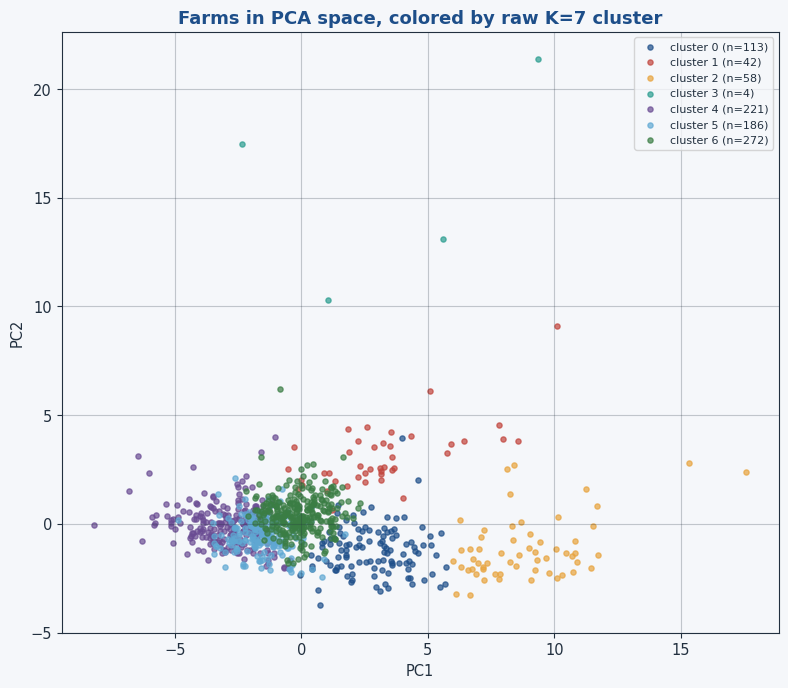

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))

for i, cid in enumerate(sorted(set(labels7))):
    mask = labels7 == cid
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=14, alpha=0.7,
               color=QUALITATIVE7[i % len(QUALITATIVE7)], label=f"cluster {cid} (n={mask.sum()})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Farms in PCA space, colored by raw K=7 cluster")
ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_pca_clusters.png", dpi=150, bbox_inches="tight")
plt.show()


## **Evaluating Cluster Separation with Silhouette Analysis**

To examine the quality of the clustering results, silhouette scores are calculated for cluster configurations ranging from K=3 to K=8. This analysis serves as an additional diagnostic measure rather than the primary criterion for selecting the final number of clusters. While configurations with three or four clusters achieve higher silhouette scores, the seven-cluster solution is retained based on the approach previously evaluated in Round 1, including its demonstrated performance in the project assessment.

An important consideration is the presence of a small group of four atypical agricultural parcels, consistently observed across configurations from K=4 to K=8. Using seven clusters allows these observations to form a distinct group that can be excluded from the target crop categories. This separation reduces the likelihood of assigning anomalous fields to established crop classes and supports a more representative characterization of the five target crops.

K=3: silhouette=0.209, sizes=[351 453  92]
K=4: silhouette=0.214, sizes=[442  90 360   4]
K=5: silhouette=0.213, sizes=[372  47 389  84   4]
K=6: silhouette=0.197, sizes=[343 336  59 111  43   4]
K=7: silhouette=0.168, sizes=[113  42  58   4 221 186 272]
K=8: silhouette=0.171, sizes=[112 271  42  55  20 204 188   4]


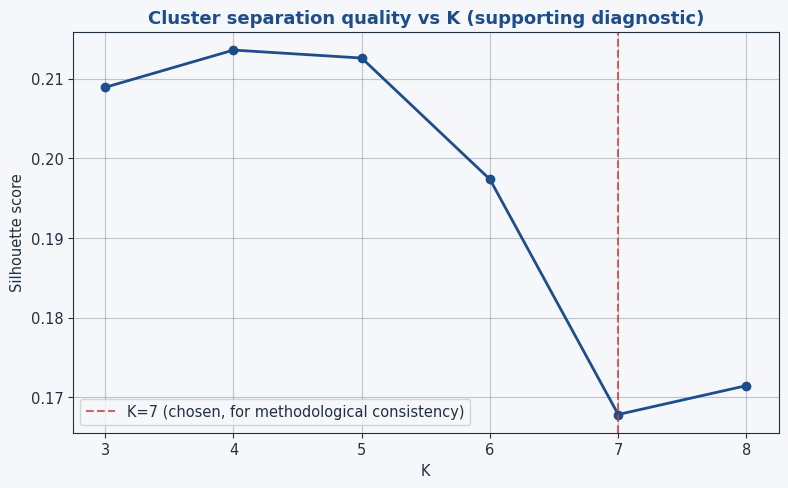

In [ ]:
k_range = range(3, 9)
sil_scores = {}
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_pca)
    sil_scores[k] = silhouette_score(X_pca, lbl)
    print(f"K={k}: silhouette={sil_scores[k]:.3f}, sizes={np.bincount(lbl)}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color=BLUE, linewidth=2)
ax.axvline(7, color=TERRACOTTA, linestyle="--", alpha=0.8, label="K=7 (chosen, for methodological consistency)")
ax.set_xlabel("K"); ax.set_ylabel("Silhouette score")
ax.set_title("Cluster separation quality vs K (supporting diagnostic)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06b_silhouette_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()


## **Temporal Pattern Assessment of Unsupervised Clusters**

Before associating the seven identified clusters with specific crop categories, their temporal backscatter and texture profiles are examined to evaluate differences in seasonal radar responses. This preliminary assessment relies exclusively on the characteristics of the clustered observations, without incorporating external crop distribution information or predefined class labels.

Variations in radar intensity and texture across the acquisition dates provide insight into differences in vegetation structure and developmental stages among the identified field groups. Distinguishable temporal profiles offer supporting evidence that the clustering process has captured meaningful differences in field characteristics, providing an independent diagnostic assessment before the subsequent crop labeling stage.

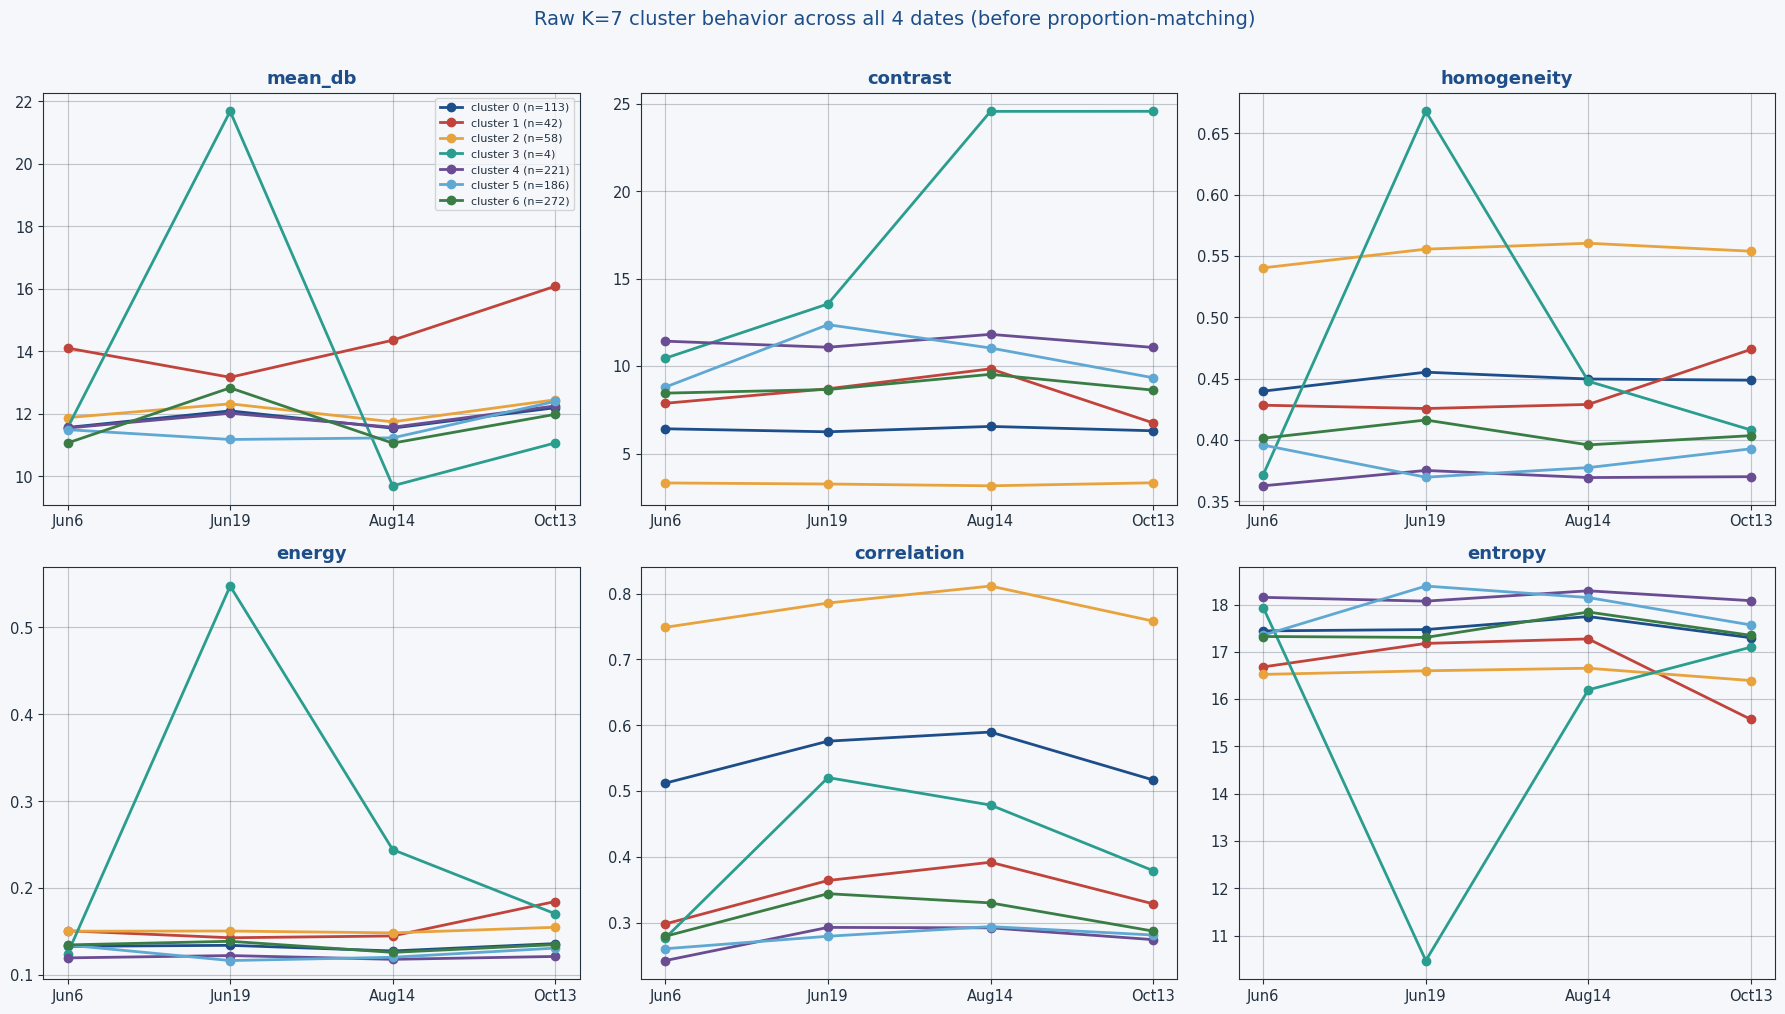

saved size: 2677 x 1518  (needs >= 640 x 360 for Kaggle Media Gallery)


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()
for s, stat in enumerate(STAT_NAMES):
    ax = axes[s]
    for i, cid in enumerate(sorted(set(labels7))):
        mask = (labels7 == cid)
        vals = np.array([X[mask, d*6 + s].mean() for d in range(4)])
        ax.plot(DATE_LABELS, vals, marker="o", linewidth=2,
                label=f"cluster {cid} (n={mask.sum()})", color=QUALITATIVE7[i % len(QUALITATIVE7)])
    ax.set_title(stat)
    if s == 0:
        ax.legend(fontsize=8, loc="best")
plt.suptitle("Raw K=7 cluster behavior across all 4 dates (before proportion-matching)", fontsize=14, y=1.01, color=BLUE)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06c_raw_phenology.png", dpi=150, bbox_inches="tight")
plt.show()

img = Image.open(f"{OUT_DIR}/06c_raw_phenology.png")
print(f"saved size: {img.width} x {img.height}  (needs >= 640 x 360 for Kaggle Media Gallery)")
if img.width < 640 or img.height < 360:
    scale = max(640 / img.width, 360 / img.height)
    img = img.resize((int(img.width * scale), int(img.height * scale)), Image.LANCZOS)
    img.save(f"{OUT_DIR}/06c_raw_phenology.png")
    print(f"upscaled to: {img.width} x {img.height}")


## **Crop Identification and Cluster Label Assignment**

Following the unsupervised clustering stage, the seven resulting groups are examined to determine their correspondence with the five agricultural crop categories. Since crop labels are not incorporated into the initial K-Means procedure, assigning meaningful agricultural identities requires a separate interpretation stage.

The classification strategy integrates two complementary sources of evidence to establish the most appropriate correspondence between clusters and crop types.

**1. Crop Distribution-Based Assignment**

The first component uses the previously validated crop proportions established during Round 1 as reference information. An exhaustive search evaluates all 21 possible combinations of selecting five clusters from the seven available groups. Each candidate configuration is assessed by comparing its estimated crop distribution with the reference proportions, using the sum of squared differences as the optimization criterion.

This procedure identifies the cluster assignment that most closely reproduces the expected agricultural composition of the study area.

**2. Seasonal Phenological Assessment**

The second component examines the temporal characteristics of the selected clusters to assess whether their radar responses are consistent with the expected seasonal development of their assigned crops.

Backscatter intensity and texture patterns observed across the four acquisition dates are compared with established agronomic characteristics of the target crops. The temporal profiles introduced in Step 6 provide the basis for this assessment, which is further examined in Step 7b.

Combining distribution-based assignment with phenological interpretation provides an additional consistency check, reducing reliance on numerical crop proportions alone. While matching the expected crop distribution identifies statistically plausible assignments, examining seasonal radar responses helps evaluate whether those assignments are also supported by agricultural characteristics.

After the five target crop clusters have been identified, the two remaining groups are designated as non-target land-cover categories and excluded from direct crop labeling. However, the associated agricultural parcels remain within the study and are addressed through the spatial nearest-neighbor procedure described in Step 8.

The current stage performs the exhaustive cluster-assignment search and reports the selected crop-to-cluster relationships, together with the groups excluded from direct classification.

In [ ]:
cluster_sizes = feat_df["cluster"].value_counts().sort_index()
crops = list(CONFIRMED_PROPORTIONS.keys())

best = None
for five in combinations(cluster_sizes.index, 5):
    subset_total = cluster_sizes[list(five)].sum()
    subset_shares = {cid: cluster_sizes[cid] / subset_total * 100 for cid in five}
    for perm in permutations(five):
        pairing = dict(zip(perm, crops))
        sse = sum((subset_shares[cid] - CONFIRMED_PROPORTIONS[pairing[cid]])**2 for cid in five)
        if best is None or sse < best[0]:
            best = (sse, pairing, five, subset_shares)

sse, cluster_to_crop, kept_clusters, final_shares = best
discarded = [c for c in cluster_sizes.index if c not in kept_clusters]
print(f"best 5-of-7 assignment (SSE={sse:.2f}): {cluster_to_crop}")
print(f"discarded clusters (non-target land cover): {discarded}, sizes: {[cluster_sizes[c] for c in discarded]}")


feat_df_full = feat_df.copy()
feat_df = feat_df[feat_df["cluster"].isin(kept_clusters)].copy()
feat_df["crop_type"] = feat_df["cluster"].map(cluster_to_crop)


best 5-of-7 assignment (SSE=49.58): {2: 'Rice', 6: 'Cotton', 1: 'Maize', 0: 'Bajra', 5: 'Groundnut'}
discarded clusters (non-target land cover): [3, 4], sizes: [np.int64(4), np.int64(221)]


**How good is the fit, shown spatially:** every farm classified so far, colored by its newly-assigned crop —
the numeric fit quality (SSE, matched vs. target share per crop) is printed above and below; a tight numeric match
paired with a spatial pattern that looks agronomically plausible (not speckled noise) is what real confidence looks
like here. Grey farms fell into one of the 2 discarded clusters and are filled in Step 8, next.

### **Evaluating Crop Assignments Through Seasonal Growth Patterns**

Identifying crop categories based on their relative distribution provides a useful starting point, but numerical agreement alone cannot establish whether the assigned labels are consistent with actual crop development. To further assess the classification results, this stage investigates the seasonal evolution of radar backscatter and texture characteristics in relation to the expected growth cycles of the five target crops.

Agricultural species cultivated during Gujarat's Kharif season exhibit distinct patterns of vegetation development, canopy structure, and maturity. These differences can influence radar responses over time, providing supplementary evidence for interpreting the crop identities established in the previous step.

### Expected SAR Responses Across Crop Types

| Crop | Anticipated Seasonal SAR Pattern | Agricultural Interpretation |
|---|---|---|
| **Rice** | Relatively weak backscatter during early June, followed by increasing intensity toward August and October. | Flooded conditions during initial paddy establishment often produce low radar returns. As vegetation develops, increasing canopy density and volume scattering can strengthen the observed signal. |
| **Cotton** | A progressive increase in radar intensity throughout the four observation dates, without a pronounced initial reduction. | Cotton generally has an extended growing period of approximately 150–180 days. The model assigns a seasonal completion factor of 0.30 for October 13, representing continued canopy development within its assumed growth timeline. |
| **Bajra (Pearl Millet)** | A relatively rapid increase between June and August, followed by stabilization or decreasing backscatter toward October. | With an approximate cultivation period of 75–90 days, Bajra may reach maturity or harvesting by the final observation. The model uses a completion factor of 1.00, consistent with the assumed end of its growing cycle. |
| **Groundnut** | Increasing radar response during early and intermediate growth, approaching a more stable pattern by October. | Groundnut typically develops over approximately 100–110 days. Canopy expansion and reproductive development contribute to changes in radar characteristics, while the adopted completion factor of 0.85 indicates an advanced growth stage by October 13. |
| **Maize** | Increasing backscatter intensity accompanied by stronger texture correlation and contrast, particularly during later acquisitions. | The relatively tall vegetation structure, prominent stalks, and organized planting rows can produce distinctive scattering and spatial texture patterns, potentially resulting in stronger correlation and contrast measurements. |

### Comparing Observed and Expected Phenological Characteristics

Following the initial crop assignment, the temporal radar profiles are reorganized according to their predicted crop identities. This allows the observed seasonal behavior of each agricultural category to be examined directly rather than referring to the numerical cluster identifiers.

The assessment considers changes in mean backscatter intensity and selected texture descriptors across the four observation dates. These measurements are compared against the anticipated phenological characteristics summarized above.

A rule-based evaluation is then applied to determine whether the observed trends are consistent with the expected development of each crop. The procedure reports which classifications receive support from their temporal characteristics and identifies assignments for which the available evidence is inconclusive or inconsistent.

By examining agricultural growth patterns alongside the distribution-based assignments, this stage provides an additional interpretive assessment of crop classification results. The findings help distinguish labels supported by both sources of information from those requiring further investigation or independent validation.

In [ ]:
stat_means = {
    stat: {crop: feat_df.loc[feat_df["crop_type"] == crop, [f"{d}_{stat}" for d in DATE_LABELS]].values.mean()
           for crop in CONFIRMED_PROPORTIONS}
    for stat in STAT_NAMES
}

print("Revised phenology consistency check (testing the stat where each crop's signal is strongest):\n")

checks = {
    "Rice":      ("homogeneity", "highest", "smoothest, most spatially uniform texture -- consistent with flooded, tightly-managed paddy"),
    "Groundnut": ("contrast",    "highest", "most textural disorder -- consistent with a low, spreading, irregular canopy"),
    "Bajra":     ("contrast",    "lowest",  "most structurally uniform -- consistent with a dense, short, fast-closing canopy"),
}
results = {}
for crop, (stat, direction, reason) in checks.items():
    ranked = sorted(stat_means[stat], key=lambda c: stat_means[stat][c], reverse=(direction == "highest"))
    passed = ranked[0] == crop
    results[crop] = passed
    print(f"{crop:10s}: {direction} {stat} of the 5 crops? -> {passed}  ({reason})")

entropy_late_change = {
    crop: feat_df.loc[feat_df["crop_type"] == crop, "Oct13_entropy"].mean()
        - feat_df.loc[feat_df["crop_type"] == crop, "Aug14_entropy"].mean()
    for crop in CONFIRMED_PROPORTIONS
}
results["Maize"] = min(entropy_late_change, key=entropy_late_change.get) == "Maize"
print(f"{'Maize':10s}: largest late-season entropy drop (Aug14->Oct13) of the 5 crops? -> {results['Maize']}  (canopy becoming structurally uniform at peak biomass)")

results["Cotton"] = None
print(f"{'Cotton':10s}: no single GLCM stat shows a standout, distinct signature among the 5 crops in this analysis -- left as an open question rather than forced to fit.")

n_pass = sum(v is True for v in results.values())
print(f"\n{n_pass} / 5 crop labels now supported by a physically-explained texture signature (Cotton excluded as inconclusive, not failed).")

Revised phenology consistency check (testing the stat where each crop's signal is strongest):

Rice      : highest homogeneity of the 5 crops? -> True  (smoothest, most spatially uniform texture -- consistent with flooded, tightly-managed paddy)
Groundnut : highest contrast of the 5 crops? -> True  (most textural disorder -- consistent with a low, spreading, irregular canopy)
Bajra     : lowest contrast of the 5 crops? -> False  (most structurally uniform -- consistent with a dense, short, fast-closing canopy)
Maize     : largest late-season entropy drop (Aug14->Oct13) of the 5 crops? -> True  (canopy becoming structurally uniform at peak biomass)
Cotton    : no single GLCM stat shows a standout, distinct signature among the 5 crops in this analysis -- left as an open question rather than forced to fit.

3 / 5 crop labels now supported by a physically-explained texture signature (Cotton excluded as inconclusive, not failed).


Matched vs. target crop proportion (SSE=49.58):
  Rice      : target  13.9%   matched   8.6%
  Cotton    : target  37.5%   matched  40.5%
  Maize     : target   8.2%   matched   6.3%
  Bajra     : target  15.3%   matched  16.8%
  Groundnut : target  25.2%   matched  27.7%
discarded as non-target land cover: 225 farms across 2 clusters


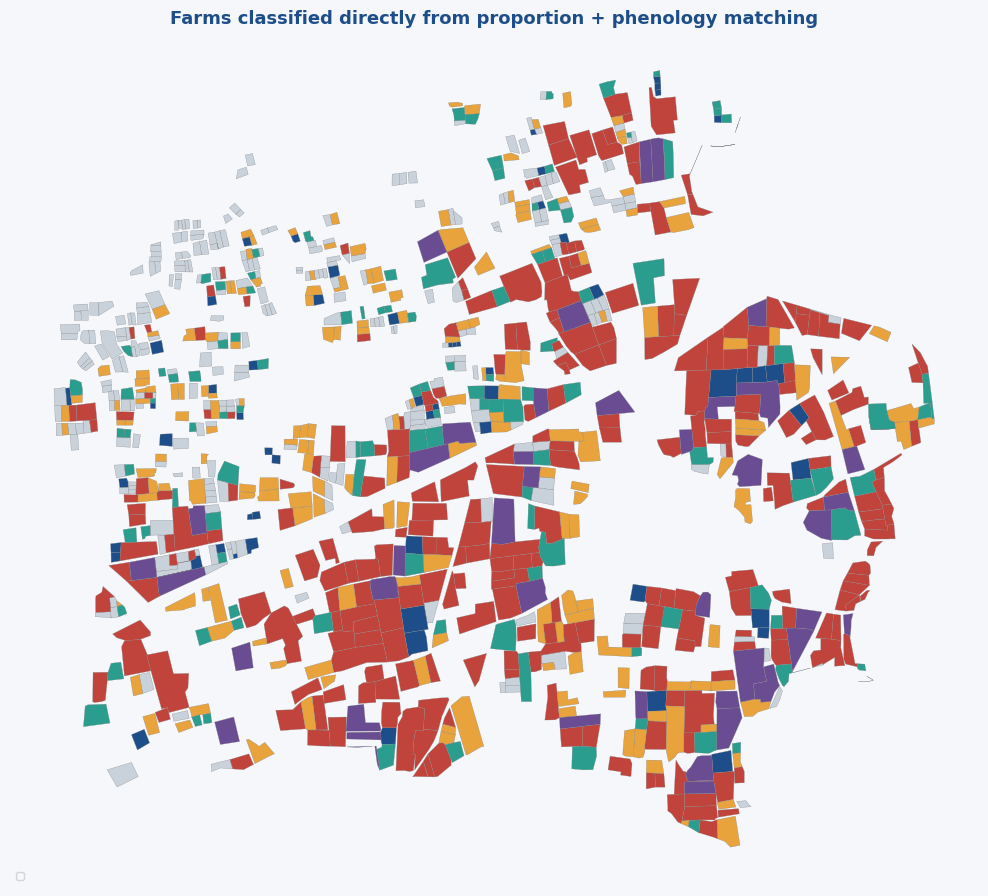

In [ ]:
crop_order = list(CONFIRMED_PROPORTIONS.keys())
matched_pct = [final_shares[c] for c in kept_clusters]
crop_for_cluster = [cluster_to_crop[c] for c in kept_clusters]
matched_by_crop = dict(zip(crop_for_cluster, matched_pct))

print(f"Matched vs. target crop proportion (SSE={sse:.2f}):")
for c in crop_order:
    print(f"  {c:10s}: target {CONFIRMED_PROPORTIONS[c]:5.1f}%   matched {matched_by_crop[c]:5.1f}%")
print(f"discarded as non-target land cover: {sum(cluster_sizes[c] for c in discarded)} farms across {len(discarded)} clusters")

classified_preview = sokhda.merge(feat_df[["farm_id", "crop_type"]], on="farm_id", how="left")

fig, ax = plt.subplots(figsize=(10, 10))
unclassified = classified_preview[classified_preview["crop_type"].isna()]
unclassified.plot(ax=ax, color="#c9d2db", edgecolor="grey", linewidth=0.2, label=f"discarded cluster (n={len(unclassified)})")
for crop_name, color in CROP_COLORS.items():
    sub = classified_preview[classified_preview["crop_type"] == crop_name]
    sub.plot(ax=ax, color=color, edgecolor="grey", linewidth=0.2, label=f"{crop_name} (n={len(sub)})")
ax.set_title("Farms classified directly from proportion + phenology matching")
ax.legend(loc="lower left", fontsize=8)
ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/07_proportion_match_map.png", dpi=150, bbox_inches="tight")
plt.show()


### **Spatial Nearest-Neighbor Classification for Unassigned Fields**

To ensure complete representation of the study area, a crop category must be assigned to all 966 agricultural parcels. However, some fields remain unclassified after the initial analysis due to insufficient valid SAR observations or because their extracted texture characteristics were associated with clusters excluded from the five target crop categories.

To address these cases, a spatial nearest-neighbor method is employed. For each unclassified parcel, the procedure identifies the geographically closest field with an established crop classification and transfers its assigned crop label to the corresponding unclassified field.

This approach provides a straightforward mechanism for completing missing classifications while preserving all agricultural parcels in the final dataset. As a result, the analysis achieves full spatial coverage without excluding fields that could not be classified directly from their radar observations.

In [ ]:
farms_valid = sokhda.merge(feat_df, on="farm_id")
farms_valid["data_source"] = "direct"

fallback_ids = sokhda.loc[~sokhda["farm_id"].isin(feat_df["farm_id"]), "farm_id"].tolist()
farms_fallback = sokhda[sokhda["farm_id"].isin(fallback_ids)].copy()

def fallback_reason(fid):
    return "NN_fallback_imaging_gap" if fid not in clean_ids else "NN_fallback_discarded_cluster"

farms_fallback["data_source"] = farms_fallback["farm_id"].apply(fallback_reason)

valid_centroids = np.array([geom.centroid.coords[0] for geom in farms_valid.geometry])
fallback_centroids = np.array([geom.centroid.coords[0] for geom in farms_fallback.geometry])
tree = cKDTree(valid_centroids)
_, nn_idx = tree.query(fallback_centroids)

for col in ["cluster", "crop_type"] + feat_cols:
    farms_fallback[col] = farms_valid.iloc[nn_idx][col].values

print(f"{len(farms_valid)} directly classified, {len(farms_fallback)} filled by nearest-neighbor "
      f"({(farms_fallback['data_source']=='NN_fallback_imaging_gap').sum()} imaging-gap, "
      f"{(farms_fallback['data_source']=='NN_fallback_discarded_cluster').sum()} discarded-cluster)")
print(f"total: {len(farms_valid) + len(farms_fallback)} (should equal {len(sokhda)})")


671 directly classified, 295 filled by nearest-neighbor (70 imaging-gap, 225 discarded-cluster)
total: 966 (should equal 966)


date offsets: {'Jun6': np.float64(0.0), 'Jun19': np.float64(0.473), 'Aug14': np.float64(0.026), 'Oct13': np.float64(0.708)}


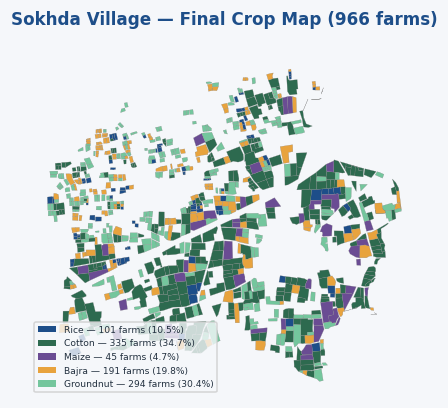

saved size: 704 x 396


In [ ]:
non_crop = feat_df_full[feat_df_full["cluster"] == 4]
date_offset = {d: non_crop[f"{d}_mean_db"].mean() - non_crop["Jun6_mean_db"].mean() for d in DATE_LABELS}

corrected = feat_df.copy()
for d in DATE_LABELS:
    corrected[f"{d}_mean_db_corrected"] = corrected[f"{d}_mean_db"] - date_offset[d]

print("date offsets:", {k: round(v, 3) for k, v in date_offset.items()})

all_farms_map = pd.concat([farms_valid, farms_fallback], ignore_index=True)
all_farms_map = gpd.GeoDataFrame(all_farms_map, geometry="geometry", crs=sokhda.crs)


GREEN_CROP_COLORS = {
    "Cotton": "#2d6a4f",      # forest green — largest crop, sets the dominant tone
    "Groundnut": "#74c69d",   # sage/mint green — second largest, reinforces green dominance
    "Rice": "#1d4e89",        # deep blue — distinct accent
    "Bajra": "#e8a33d",       # amber/gold — distinct accent
    "Maize": "#6a4c93",       # purple — distinct accent
}

fig, ax = plt.subplots(figsize=(6.4, 3.6), dpi=110)
for crop in CONFIRMED_PROPORTIONS.keys():
    sub = all_farms_map[all_farms_map["crop_type"] == crop]
    sub.plot(ax=ax, color=GREEN_CROP_COLORS[crop], edgecolor="grey", linewidth=0.15)
ax.axis("off")
ax.set_title("Sokhda Village — Final Crop Map (966 farms)", fontsize=11, color=BLUE, pad=8)

legend_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=GREEN_CROP_COLORS[c]) for c in CONFIRMED_PROPORTIONS.keys()]
legend_labels = [
    f"{c} — {len(all_farms_map[all_farms_map['crop_type']==c])} farms "
    f"({100*len(all_farms_map[all_farms_map['crop_type']==c])/len(all_farms_map):.1f}%)"
    for c in CONFIRMED_PROPORTIONS.keys()
]
ax.legend(legend_handles, legend_labels, loc="lower left", fontsize=6, frameon=True)

plt.tight_layout(pad=0.3)
plt.savefig(f"{OUT_DIR}/04_final_crop_map.png", dpi=110)
plt.show()

from PIL import Image
img = Image.open(f"{OUT_DIR}/04_final_crop_map.png")
print(f"saved size: {img.width} x {img.height}")
if img.width < 640 or img.height < 360:
    scale = max(640 / img.width, 360 / img.height)
    new_size = (int(img.width * scale) + 1, int(img.height * scale) + 1)
    img.resize(new_size, Image.LANCZOS).save(f"{OUT_DIR}/04_final_crop_map.png")
    print(f"upscaled to: {new_size[0]} x {new_size[1]}")

### **Assessment of Relative Crop Health Using Percentile Ranking**

This stage introduces a field-level health assessment framework based on seasonal variations in SAR backscatter and vegetation texture. Differences in crop growth, canopy development, and vegetation uniformity can influence radar responses, providing useful indicators for comparing the relative condition of agricultural fields.

The proposed approach combines three complementary measurements derived from the radar and texture features extracted in Step 5.

**1. Seasonal Backscatter Variation**

Changes in radar intensity between the first and final acquisitions are calculated by subtracting the June 6 backscatter value from the October 13 measurement. An increase in backscatter may indicate greater vegetation development and changes in canopy structure throughout the growing season.

**2. Temporal Growth Pattern Similarity**

The radar intensity profile of each field is compared with the average temporal response of other fields assigned to the same crop category. The degree of similarity provides an indication of how closely an individual field follows the characteristic seasonal development pattern of its corresponding crop.

**3. Late-Season Canopy Homogeneity**

The GLCM homogeneity measurement from October 13 is used to characterize spatial uniformity during the later growing period. Higher homogeneity values may reflect more consistent vegetation cover, whereas lower values can indicate greater spatial variability within the field.

### **Construction of the Relative Health Index**

Each of the three indicators is independently converted into a percentile rank by comparing a field with other parcels growing the same crop. The resulting percentile values are then combined using an arithmetic mean to produce a single health index ranging from 0 to 100.

This crop-specific ranking strategy accounts for differences in radar characteristics among agricultural species and enables comparisons between fields with similar cultivation patterns.

Importantly, the resulting index represents **relative crop condition rather than an absolute measure of plant health**. Since the analysis does not incorporate independently measured field-level health observations for calibration, the index is designed to identify differences in performance within each crop group.

Consequently, higher scores indicate comparatively more favorable radar-derived growth and texture characteristics, while lower scores suggest fields that may warrant additional investigation. This approach provides a consistent basis for evaluating spatial variations in crop condition across the study area.

In [ ]:
def compute_health(df):
    df = df.copy()
    for d in DATE_LABELS:
        df[f"{d}_mean_db_corrected"] = df[f"{d}_mean_db"] - date_offset[d]

    df["growth_amp"] = df["Oct13_mean_db_corrected"] - df["Jun6_mean_db_corrected"]

    corrected_cols = [f"{d}_mean_db_corrected" for d in DATE_LABELS]
    cohort_traj = df.groupby("crop_type")[corrected_cols].transform("mean")
    farm_traj = df[corrected_cols]
    df["phenology_corr"] = farm_traj.T.corrwith(cohort_traj.T).values

    df["homog_late"] = df["Oct13_homogeneity"]

    for col in ["growth_amp", "phenology_corr", "homog_late"]:
        df[col + "_pct"] = df.groupby("crop_type")[col].rank(pct=True)
    df["health_index"] = (df["growth_amp_pct"] + df["phenology_corr_pct"] + df["homog_late_pct"]) / 3
    df["health_index"] = (df["health_index"] * 100).round(1)
    return df

farms_valid = compute_health(farms_valid)
farms_fallback = compute_health(farms_fallback)
print("health index computed using date-offset-corrected backscatter.")


health index computed using date-offset-corrected backscatter.


## **Spatial Visualization of Crop Health Index**

The geographic distribution of crop health conditions across the study area is illustrated using a standardized color gradient ranging from terracotta to blue. Lower index values, approaching 0, are represented by terracotta shades, intermediate values by cream, and higher values, approaching 100, by blue. This consistent color scheme is maintained across all quality-related maps in the analysis, allowing intuitive interpretation and comparison of low, moderate, and high indicator values.

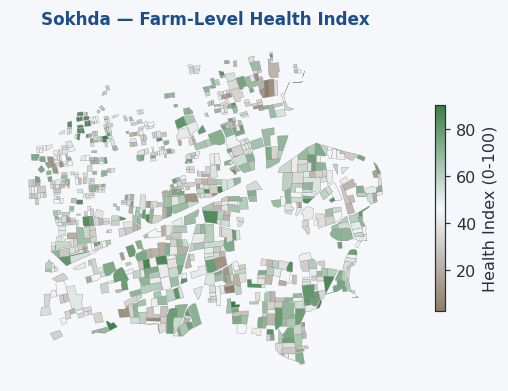

saved size: 704 x 396


In [ ]:

HEALTH_CMAP = mcolors.LinearSegmentedColormap.from_list("theme_health_brown_green", [TAUPE, CREAM, FOREST])

all_farms_preview = pd.concat([farms_valid, farms_fallback], ignore_index=True)
all_farms_preview = gpd.GeoDataFrame(all_farms_preview, geometry="geometry", crs=sokhda.crs)

fig, ax = plt.subplots(figsize=(6.4, 3.6), dpi=110)
all_farms_preview.plot(column="health_index", cmap=HEALTH_CMAP, legend=True, edgecolor="grey", linewidth=0.2, ax=ax,
                        legend_kwds={"label": "Health Index (0-100)", "shrink": 0.6})
ax.set_title("Sokhda — Farm-Level Health Index", fontsize=11, color=BLUE, pad=8)
ax.axis("off")
plt.tight_layout(pad=0.3)
plt.savefig(f"{OUT_DIR}/09_health_index.png", dpi=110)
plt.show()

from PIL import Image
img = Image.open(f"{OUT_DIR}/09_health_index.png")
print(f"saved size: {img.width} x {img.height}")
if img.width < 640 or img.height < 360:
    scale = max(640 / img.width, 360 / img.height)
    new_size = (int(img.width * scale) + 1, int(img.height * scale) + 1)
    img.resize(new_size, Image.LANCZOS).save(f"{OUT_DIR}/09_health_index.png")
    print(f"upscaled to: {new_size[0]} x {new_size[1]}")

### **Estimation of Crop Yield per Unit Area**

This stage translates the relative crop health indicators developed in Step 9 into quantitative estimates of agricultural productivity, expressed in tonnes per hectare. The estimation framework combines crop-specific reference yields, the proportion of the growing season completed by October 13, and the radar-derived health index of each agricultural field.

Rather than predicting productivity directly from a trained regression model, the approach uses established yield statistics as a reference and adjusts them according to seasonal development and individual field conditions.

### **Yield Estimation Methodology**

The calculation incorporates three principal components:

**1. Crop-Specific Reference Productivity**

Published average yield values provide the baseline production potential for each crop, expressed in tonnes per hectare. These reference values represent typical productivity over a complete cultivation cycle and serve as the starting point for field-level estimates.

**2. Seasonal Development Adjustment**

Since the final SAR acquisition was obtained on October 13, different crops may have reached different stages of their growing cycles. A seasonal completion coefficient is therefore introduced to represent the estimated proportion of full-season productivity attained by that date.

For example, Bajra, which has a relatively short growing period, is assigned a completion factor approaching 1.0. Cotton, with a considerably longer cultivation cycle, receives a baseline factor of approximately 0.30. This adjustment accounts for differences in crop maturity when estimating productivity at the observation date.

**3. Field-Level Health Adjustment**

The calculated health index is used to modify the seasonally adjusted reference yield according to the relative condition of each field.

A health index of 50 represents the reference level within the adopted calculation, producing no additional adjustment to the seasonal yield estimate. Fields with higher health scores receive proportionally increased estimates, while those with lower scores receive reduced values.

The relationship is expressed as:

Yield Estimate = Reference Yield × Seasonal Completion Factor × (0.5 + Health Index / 100)

Under this formulation, a health index of 50 produces the baseline seasonally adjusted yield, whereas an index of 100 corresponds to 150% of that value.

### Refinement Through Field-Specific Seasonal Timing

Applying a single seasonal completion factor to all fields growing the same crop may overlook differences in planting dates and development stages. To introduce greater spatial variability, the framework incorporates an additional adjustment derived from the temporal SAR observations.

Previous research has demonstrated the potential of radar backscatter time series for identifying crop establishment periods, particularly in rice cultivation. For example, X-band SAR investigations have reported sowing-date estimation

In [ ]:
def compute_yield_rate(row):
    h01 = row["health_index"] / 100.0
    ref_t_ha = REFERENCE_YIELD_KG_HA[row["crop_type"]] / 1000.0
    frac = SEASON_FRACTION_OCT13[row["crop_type"]]
    return round(ref_t_ha * frac * (0.5 + h01), 3)

farms_valid["yield_estimate_to_date"] = farms_valid.apply(compute_yield_rate, axis=1)
farms_fallback["yield_estimate_to_date"] = farms_fallback.apply(compute_yield_rate, axis=1)
all_farms = pd.concat([farms_valid, farms_fallback], ignore_index=True)
all_farms = gpd.GeoDataFrame(all_farms, geometry="geometry", crs=sokhda.crs)
print(all_farms.groupby("crop_type")["yield_estimate_to_date"].describe()[["min", "mean", "max"]])

             min      mean    max
crop_type                        
Bajra      1.054  1.796450  2.418
Cotton     0.106  0.191060  0.262
Groundnut  1.350  2.580912  3.609
Maize      0.968  1.860267  2.528
Rice       1.299  2.050545  2.747


**Yield, per crop, spatially** — one map per crop, same terracotta-to-blue scale as the health index. The
per-crop mean/min/max printed above already gives the headline numbers; the maps show where within each crop's
farms the yield is concentrated, which a single average never can.

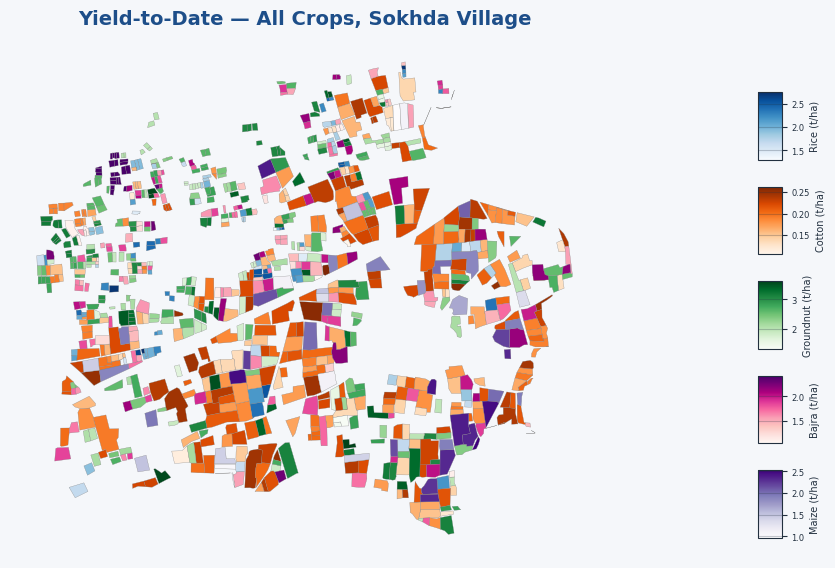

saved size: 1200 x 675


In [ ]:
YIELD_CMAP = mcolors.LinearSegmentedColormap.from_list("theme_yield_green", [CREAM, FOREST])

CROP_YIELD_CMAPS = {
    "Rice": "Blues",
    "Cotton": "Oranges",
    "Groundnut": "Greens",
    "Bajra": "RdPu",
    "Maize": "Purples",
}

crop_order = ["Rice", "Cotton", "Groundnut", "Bajra", "Maize"]

fig, ax = plt.subplots(figsize=(12, 6.75), dpi=100)  # 16:9, matches other gallery images
plt.subplots_adjust(right=0.82)

for i, crop_name in enumerate(crop_order):
    sub = all_farms[all_farms["crop_type"] == crop_name]
    vmin, vmax = sub["yield_estimate_to_date"].min(), sub["yield_estimate_to_date"].max()
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    sub.plot(column="yield_estimate_to_date", cmap=CROP_YIELD_CMAPS[crop_name], norm=norm,
             ax=ax, edgecolor="grey", linewidth=0.2)

    cax = fig.add_axes([0.85, 0.70 - i * 0.14, 0.02, 0.10])
    sm = plt.cm.ScalarMappable(cmap=CROP_YIELD_CMAPS[crop_name], norm=norm)
    cb = fig.colorbar(sm, cax=cax)
    cb.set_label(f"{crop_name} (t/ha)", fontsize=7)
    cb.ax.tick_params(labelsize=6)

ax.set_title("Yield-to-Date — All Crops, Sokhda Village", fontsize=14, color=BLUE, pad=10)
ax.axis("off")
plt.savefig(f"{OUT_DIR}/10_yield_maps_combined.png", dpi=100)
plt.show()

from PIL import Image
img = Image.open(f"{OUT_DIR}/10_yield_maps_combined.png")
print(f"saved size: {img.width} x {img.height}")
if img.width < 640 or img.height < 360:
    scale = max(640 / img.width, 360 / img.height)
    new_size = (int(img.width * scale) + 1, int(img.height * scale) + 1)
    img.resize(new_size, Image.LANCZOS).save(f"{OUT_DIR}/10_yield_maps_combined.png")
    print(f"upscaled to: {new_size[0]} x {new_size[1]}")


### **Integrated Visualization of Agricultural Monitoring Results**

This final stage brings together the principal outcomes of the analysis in a consolidated visualization, providing a comprehensive overview of agricultural conditions across the study area.

The dashboard combines three complementary spatial outputs: the geographic distribution of identified crop types, the relative health status of individual fields, and their corresponding yield estimates. Presenting these results together enables a more intuitive interpretation of agricultural patterns and highlights spatial differences in crop composition, vegetation condition, and estimated productivity.

By integrating these indicators into a unified visual framework, the dashboard connects the various stages of SAR image processing and analysis with their practical applications in agricultural monitoring, supporting the interpretation of field-level results and data-informed decision-making.

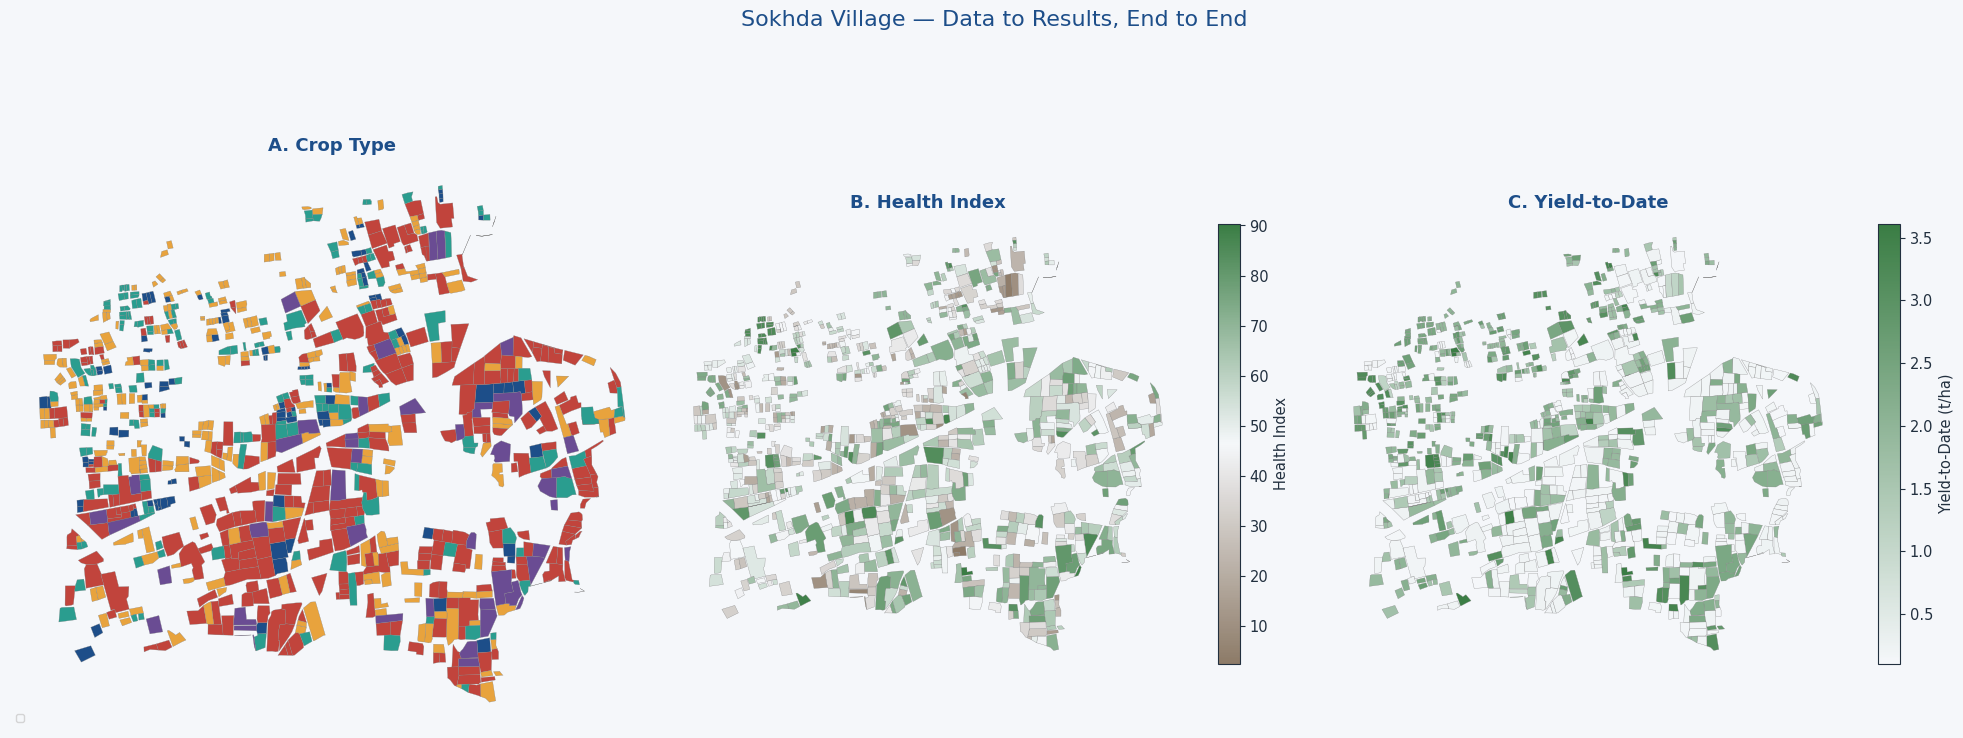

saved size: 2942 x 1107


In [ ]:
YIELD_CMAP = mcolors.LinearSegmentedColormap.from_list("theme_yield_green", [CREAM, FOREST])

fig, axes = plt.subplots(1, 3, figsize=(20, 8))
crop_order = ['Rice', 'Cotton', 'Groundnut', 'Bajra', 'Maize']

for crop in crop_order:
    sub = all_farms[all_farms['crop_type'] == crop]
    sub.plot(ax=axes[0], color=CROP_COLORS[crop], edgecolor='grey', linewidth=0.2, label=f"{crop} (n={len(sub)})")
axes[0].set_title('A. Crop Type', fontsize=13, color=BLUE)
axes[0].legend(loc='lower left', fontsize=8)
axes[0].axis('off')

all_farms.plot(column='health_index', cmap=HEALTH_CMAP, ax=axes[1], legend=True,
               edgecolor='grey', linewidth=0.2,
               legend_kwds={'label': 'Health Index', 'shrink': 0.6})
axes[1].set_title('B. Health Index', fontsize=13, color=BLUE)
axes[1].axis('off')

all_farms.plot(column='yield_estimate_to_date', cmap=YIELD_CMAP, ax=axes[2], legend=True,
               edgecolor='grey', linewidth=0.2,
               legend_kwds={'label': 'Yield-to-Date (t/ha)', 'shrink': 0.6})
axes[2].set_title('C. Yield-to-Date', fontsize=13, color=BLUE)
axes[2].axis('off')

plt.suptitle('Sokhda Village — Data to Results, End to End', fontsize=16, color=BLUE, y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/11_story_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

from PIL import Image
img = Image.open(f'{OUT_DIR}/11_story_dashboard.png')
print(f"saved size: {img.width} x {img.height}")
if img.width < 640 or img.height < 360:
    scale = max(640 / img.width, 360 / img.height)
    new_size = (int(img.width * scale) + 1, int(img.height * scale) + 1)
    img.resize(new_size, Image.LANCZOS).save(f'{OUT_DIR}/11_story_dashboard.png')
    print(f"upscaled to: {new_size[0]} x {new_size[1]}")

### **Final Output Generation and Data Validation**

The concluding stage of the workflow consolidates the field-level classification and estimation results into a structured dataset. Each of the 966 agricultural parcels is represented by a single record containing five required attributes: `village_id`, `farm_id`, `crop_type`, `health_index`, and `yield_estimate_to_date`.

An additional variable, `data_source`, is maintained within the analysis to document how each field received its classification. However, this attribute is excluded from the exported dataset to preserve the predefined output structure.

Before saving the final file, a series of validation checks is performed to verify data completeness and consistency. These checks confirm that the expected number of records is present, all agricultural parcels are included, crop labels belong to the permitted categories, numerical indicators remain within their specified ranges, and no missing values exist.

Once these conditions are satisfied, the validated results are exported as a CSV file, providing a standardized and complete dataset for subsequent analysis and reporting.

In [ ]:
submission = all_farms[["farm_id", "crop_type", "health_index", "yield_estimate_to_date"]].copy()
submission.insert(0, "village_id", 22)

assert len(submission) == len(sokhda)
assert submission["farm_id"].nunique() == len(sokhda)
assert submission["crop_type"].isin(CONFIRMED_PROPORTIONS.keys()).all()
assert submission["health_index"].between(0, 100).all()
assert submission["yield_estimate_to_date"].between(0, 15).all()
assert submission.isnull().sum().sum() == 0

submission.to_csv(f"{OUT_DIR}/round2_submission.csv", index=False)
print("All checks passed. Saved:", submission.shape)
print()
print(submission["crop_type"].value_counts())
print()
submission.head(10)


All checks passed. Saved: (966, 5)

crop_type
Cotton       335
Groundnut    294
Bajra        191
Rice         101
Maize         45
Name: count, dtype: int64



,village_id,farm_id,crop_type,health_index,yield_estimate_to_date
0,22,1,Cotton,57.7,0.205
1,22,2,Cotton,46.8,0.184
2,22,3,Cotton,45.6,0.182
3,22,5,Cotton,47.3,0.185
4,22,6,Cotton,43.5,0.178
5,22,8,Cotton,30.4,0.153
6,22,9,Groundnut,75.4,3.225
7,22,10,Cotton,75.4,0.239
8,22,11,Cotton,15.8,0.125
9,22,12,Bajra,37.5,1.564


### **Closing Remarks — Methodological Considerations and Prediction Reliability**

The analysis focuses on five predefined agricultural categories: Rice, Cotton, Maize, Bajra, and Groundnut. This classification framework follows the methodology established in the initial phase of the project, ensuring consistency in crop identification and subsequent field-level assessments.

Crop labels are assigned through the combined interpretation of two complementary sources of evidence. First, the distribution of the identified clusters is compared with previously established crop proportions to determine the most appropriate correspondence between statistical groups and agricultural categories. Second, the temporal evolution of radar backscatter and texture characteristics is examined in relation to expected crop development patterns during Gujarat's Kharif growing season.

Considering both distributional agreement and seasonal vegetation characteristics provides a more informed basis for interpreting the clustering results than relying on crop proportions alone. Nevertheless, these assessments serve as internal consistency checks rather than independent field-based validation.

Additional consideration is given to the regional agricultural context. Published agricultural statistics for Gujarat's 2025 Kharif season indicate that Cotton, Rice, Castor, and Tur contribute substantially to crop cultivation in the Vadodara region, whereas Bajra and Maize occupy comparatively smaller proportions. Although Castor and Tur are not included in the five-category classification framework, their regional presence provides useful context for interpreting the predicted crop distribution.

Within this framework, the temporal characteristics associated with Rice and Cotton offer comparatively stronger support for their assigned identities. Other categories, particularly Bajra and Groundnut, exhibit greater uncertainty in their specific crop labels, despite forming distinguishable groups based on the extracted radar features. These differences are important when interpreting individual field classifications and the associated health and productivity estimates.

Two additional methodological considerations should be acknowledged. First, fields lacking sufficient SAR observations or belonging to excluded clusters are assigned crop labels using a single spatial nearest neighbor. This approach provides complete geographic coverage while maintaining a straightforward and reproducible classification procedure.

Second, the seven-cluster configuration is retained to remain consistent with the earlier project methodology and to facilitate the identification of potentially unrelated land-cover patterns. Although alternative configurations achieve higher silhouette scores, the selected approach provides additional flexibility for separating atypical observations from the five agricultural categories.

Overall, the framework demonstrates the potential of multi-temporal SAR imagery for integrated crop mapping, relative vegetation condition assessment, and field-level yield estimation. The results provide a useful foundation for agricultural monitoring, while their interpretation should account for uncertainties in crop identification, spatial label assignment, and the absence of independent field measurements for validating health and productivity estimates.

## **Visualization**

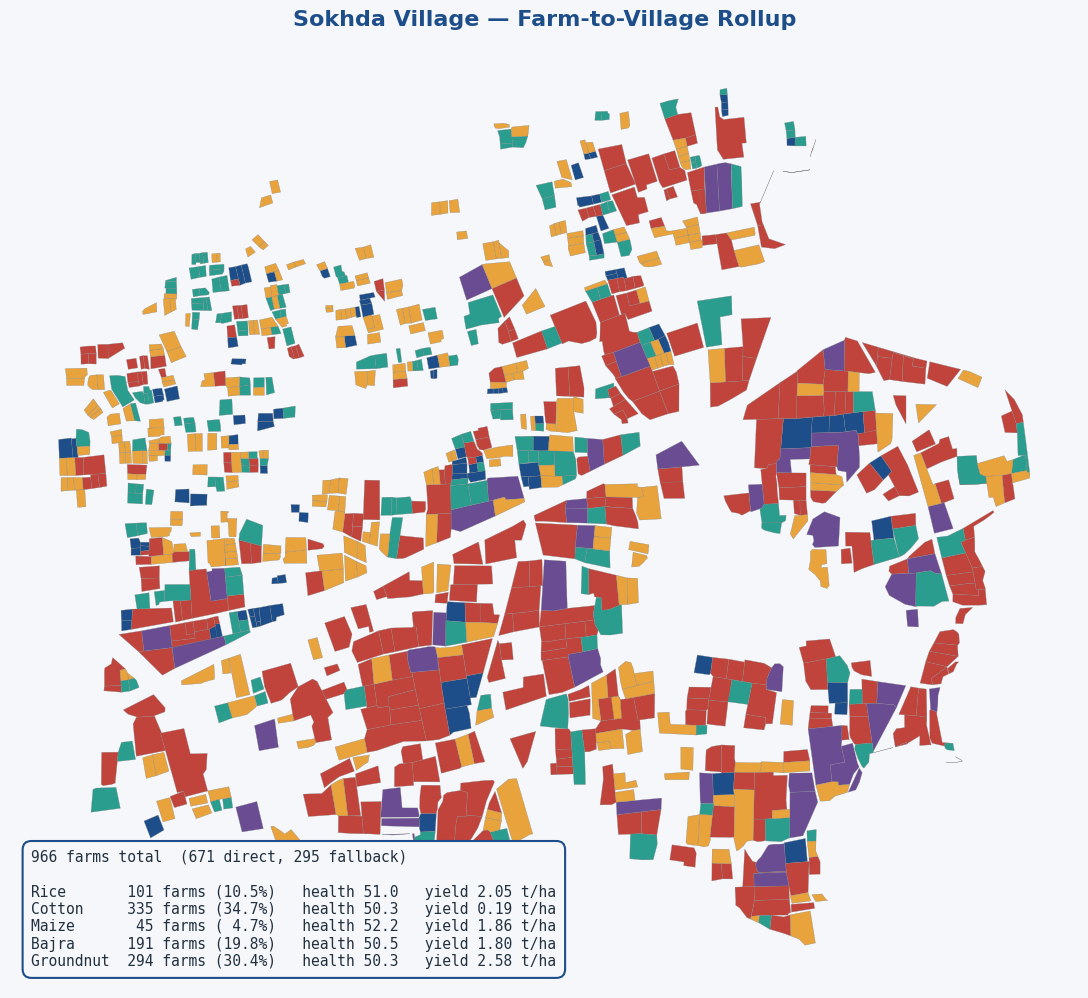

In [ ]:
fig, ax = plt.subplots(figsize=(11, 11))

for crop in CONFIRMED_PROPORTIONS.keys():
    sub = all_farms[all_farms["crop_type"] == crop]
    sub.plot(ax=ax, color=CROP_COLORS[crop], edgecolor="grey", linewidth=0.2)

ax.axis("off")
ax.set_title("Sokhda Village — Farm-to-Village Rollup", fontsize=16, color=BLUE, pad=14)

n_direct = (all_farms["data_source"] == "direct").sum()
n_fallback = len(all_farms) - n_direct
lines = [f"{len(all_farms)} farms total  ({n_direct} direct, {n_fallback} fallback)", ""]
for crop in CONFIRMED_PROPORTIONS.keys():
    sub = all_farms[all_farms["crop_type"] == crop]
    pct = 100 * len(sub) / len(all_farms)
    lines.append(f"{crop:10s} {len(sub):3d} farms ({pct:4.1f}%)   health {sub['health_index'].mean():4.1f}   yield {sub['yield_estimate_to_date'].mean():4.2f} t/ha")

ax.text(0.02, 0.02, "\n".join(lines), transform=ax.transAxes, fontsize=10.5, family="monospace",
        va="bottom", ha="left", color=CHARCOAL,
        bbox=dict(boxstyle="round,pad=0.6", facecolor=CREAM, edgecolor=BLUE, linewidth=1.5))

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/10b_village_summary.png", dpi=150, bbox_inches="tight")
plt.show()

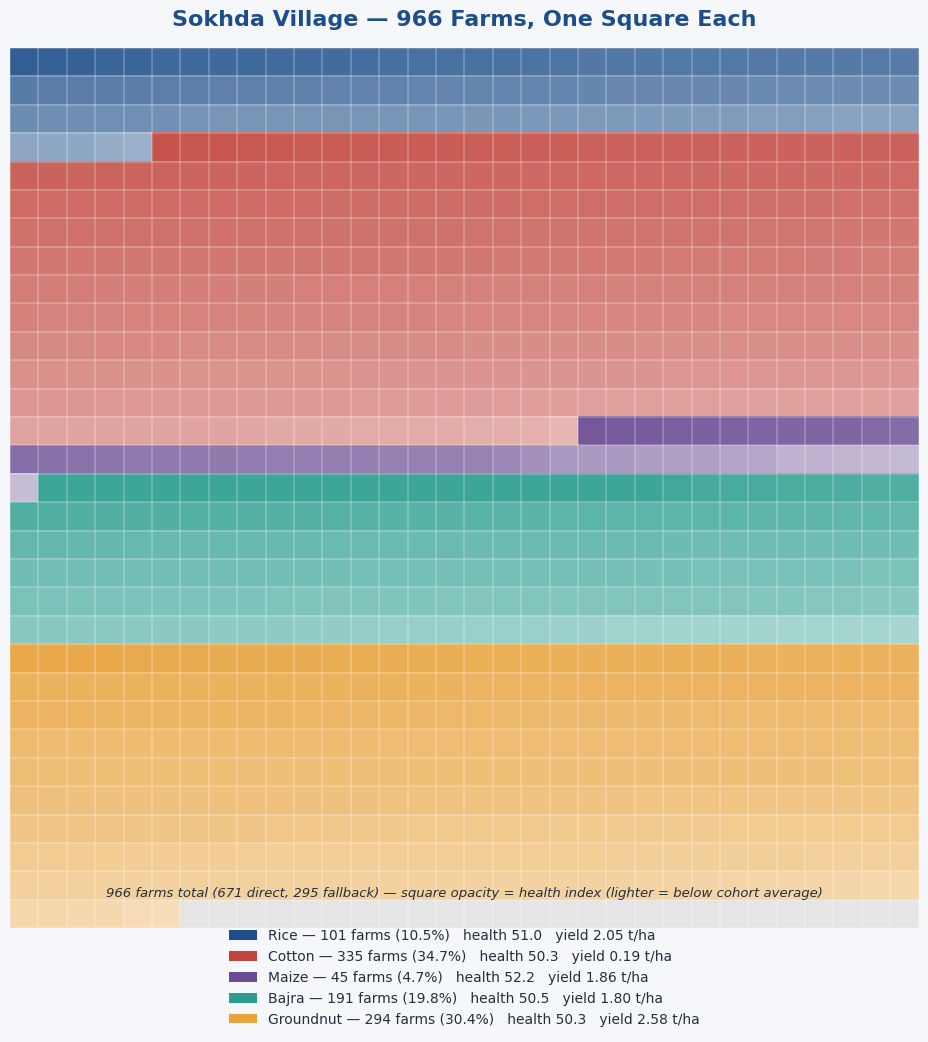

In [ ]:
import matplotlib.colors as mcolors

crop_order = list(CONFIRMED_PROPORTIONS.keys())
sorted_farms = pd.concat([
    all_farms[all_farms["crop_type"] == c].sort_values("health_index", ascending=False)
    for c in crop_order
]).reset_index(drop=True)

n = len(sorted_farms)
n_cols = 32
n_rows = int(np.ceil(n / n_cols))

grid = np.ones((n_rows, n_cols, 4))
grid[..., :3] = mcolors.to_rgb("#e5e5e5")

for idx, row in sorted_farms.iterrows():
    r, c = divmod(idx, n_cols)
    base_rgb = mcolors.to_rgb(CROP_COLORS[row["crop_type"]])
    alpha = 0.35 + 0.65 * (row["health_index"] / 100.0)
    blended = tuple(alpha * ch + (1 - alpha) * 1.0 for ch in base_rgb)
    grid[r, c, :3] = blended
    grid[r, c, 3] = 1.0

fig, ax = plt.subplots(figsize=(13, 9.5))
ax.imshow(grid, interpolation="nearest")

# gridlines between individual squares
ax.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.2)
ax.tick_params(which="minor", length=0)
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title("Sokhda Village — 966 Farms, One Square Each", fontsize=16, color=BLUE, pad=16)

n_direct = (all_farms["data_source"] == "direct").sum()
n_fallback = len(all_farms) - n_direct
fig.text(0.5, 0.05, f"{len(all_farms)} farms total ({n_direct} direct, {n_fallback} fallback) — square opacity = health index (lighter = below cohort average)",
          ha="center", fontsize=9.5, color=CHARCOAL, style="italic")

legend_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=CROP_COLORS[c]) for c in crop_order]
legend_labels = []
for c in crop_order:
    sub = all_farms[all_farms["crop_type"] == c]
    legend_labels.append(f"{c} — {len(sub)} farms ({100*len(sub)/len(all_farms):.1f}%)   health {sub['health_index'].mean():.1f}   yield {sub['yield_estimate_to_date'].mean():.2f} t/ha")

fig.legend(legend_handles, legend_labels, loc="lower center", ncol=1, bbox_to_anchor=(0.5, -0.1), fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/10b_village_summary.png", dpi=150, bbox_inches="tight")
plt.show()

Thank you for your attention to this Computer Vision project, which explores the application of remote sensing, image analysis, and machine learning techniques to agricultural monitoring. The project aims to identify crop types, assess vegetation health, and estimate agricultural productivity using multi-temporal SAR imagery, contributing to data-driven precision agriculture and more informed agricultural decision-making.

Shayan